# FIFA 21 — Exploratory Data Analysis (Visualization Only)

**Machine Learning Lab — Individual Assignment**

This notebook follows the supplied assignment in the same order: **Setup → Parts A–F → Final Summary**.  
The assignment requires that the data itself is not modified; therefore all filtering/selection below is used only for plotting or calculation, while `raw` and `clean` remain unchanged.

**Required files in the same folder as this notebook:**
- `fifa21_raw_data.csv`
- `fifa21_cleaned_data.csv`

The assignment specifies Pandas, NumPy, Matplotlib and Seaborn and requires every plot to have a title and labelled axes. fileciteturn0file0L7-L15

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

raw = pd.read_csv("fifa21_raw_data.csv")
clean = pd.read_csv("fifa21_cleaned_data.csv")

print("Raw shape:", raw.shape)
print("Cleaned shape:", clean.shape)
print("\nRaw columns:")
print(raw.columns.tolist())
print("\nCleaned columns:")
print(clean.columns.tolist())

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14544\1103686882.py:9: DtypeWarning: Columns (0: Hits) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv("fifa21_raw_data.csv")


Raw shape: (18979, 77)
Cleaned shape: (18979, 79)

Raw columns:
['photoUrl', 'LongName', 'playerUrl', 'Nationality', 'Positions', 'Name', 'Age', '↓OVA', 'POT', 'Team & Contract', 'ID', 'Height', 'Weight', 'foot', 'BOV', 'BP', 'Growth', 'Joined', 'Loan Date End', 'Value', 'Wage', 'Release Clause', 'Attacking', 'Crossing', 'Finishing', 'Heading Accuracy', 'Short Passing', 'Volleys', 'Skill', 'Dribbling', 'Curve', 'FK Accuracy', 'Long Passing', 'Ball Control', 'Movement', 'Acceleration', 'Sprint Speed', 'Agility', 'Reactions', 'Balance', 'Power', 'Shot Power', 'Jumping', 'Stamina', 'Strength', 'Long Shots', 'Mentality', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Defending', 'Marking', 'Standing Tackle', 'Sliding Tackle', 'Goalkeeping', 'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning', 'GK Reflexes', 'Total Stats', 'Base Stats', 'W/F', 'SM', 'A/W', 'D/W', 'IR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY', 'Hits']

Cleaned columns:
['ID', 'Name

## Helper functions
These helpers only inspect the data and generate plots/observations; they do not alter `raw` or `clean`.

In [4]:
def first_existing(df, *names):
    for name in names:
        if name in df.columns:
            return name
    raise KeyError(f"None of these columns were found: {names}")

def observation(text):
    display(pd.DataFrame({"Observation": [text]}))

def numeric_series(df, col):
    return pd.to_numeric(df[col], errors="coerce").dropna()

raw_ova_col = first_existing(raw, "↓OVA", "OVA")
clean_ova_col = first_existing(clean, "OVA", "↓OVA")

print("Raw OVA column:", raw_ova_col)
print("Cleaned OVA column:", clean_ova_col)

Raw OVA column: ↓OVA
Cleaned OVA column: OVA


## Part A — Know the files
The assignment asks us to compare the uncleaned and cleaned files, especially shapes, data types, missing values and the formatting of numeric-looking columns.

In [5]:
# A1 — shape and data types
print("RAW DATA")
print("Shape:", raw.shape)
display(raw.dtypes.to_frame("dtype"))

print("\nCLEANED DATA")
print("Shape:", clean.shape)
display(clean.dtypes.to_frame("dtype"))

print("\nNumeric columns in raw:")
print(raw.select_dtypes(include=np.number).columns.tolist())
print("\nText/object columns in raw:")
print(raw.select_dtypes(exclude=np.number).columns.tolist())

print("\nNumeric columns in cleaned:")
print(clean.select_dtypes(include=np.number).columns.tolist())
print("\nText/object columns in cleaned:")
print(clean.select_dtypes(exclude=np.number).columns.tolist())

observation("The cleaned file should contain more columns stored as numeric types, while the raw file contains text-formatted numeric fields such as Value, Wage, Height, Weight and Hits.")

RAW DATA
Shape: (18979, 77)


,dtype
photoUrl,str
LongName,str
playerUrl,str
Nationality,str
Positions,str
...,...
PAS,int64
DRI,int64
DEF,int64
PHY,int64



CLEANED DATA
Shape: (18979, 79)


,dtype
ID,int64
Name,str
LongName,str
photoUrl,str
playerUrl,str
...,...
DEF,int64
PHY,int64
Hits,float64
Years_at_Club,float64



Numeric columns in raw:
['Age', '↓OVA', 'POT', 'ID', 'BOV', 'Growth', 'Attacking', 'Crossing', 'Finishing', 'Heading Accuracy', 'Short Passing', 'Volleys', 'Skill', 'Dribbling', 'Curve', 'FK Accuracy', 'Long Passing', 'Ball Control', 'Movement', 'Acceleration', 'Sprint Speed', 'Agility', 'Reactions', 'Balance', 'Power', 'Shot Power', 'Jumping', 'Stamina', 'Strength', 'Long Shots', 'Mentality', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Defending', 'Marking', 'Standing Tackle', 'Sliding Tackle', 'Goalkeeping', 'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning', 'GK Reflexes', 'Total Stats', 'Base Stats', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']

Text/object columns in raw:
['photoUrl', 'LongName', 'playerUrl', 'Nationality', 'Positions', 'Name', 'Team & Contract', 'Height', 'Weight', 'foot', 'BP', 'Joined', 'Loan Date End', 'Value', 'Wage', 'Release Clause', 'W/F', 'SM', 'A/W', 'D/W', 'IR', 'Hits']

Numeric columns in cleaned:
['ID', 'Ag

,Observation
0,The cleaned file should contain more columns s...


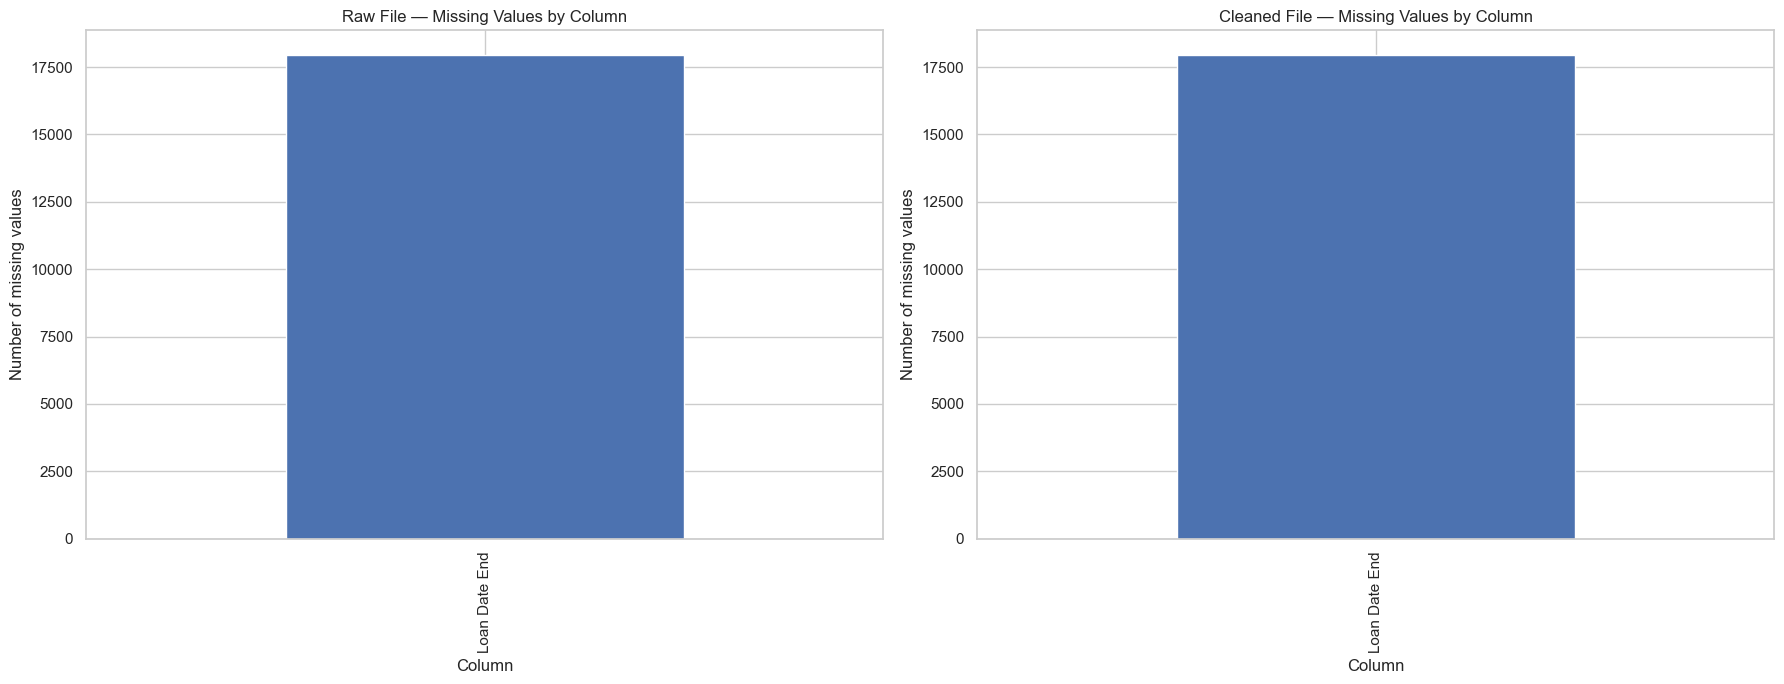

Total missing values — raw: 17966
Total missing values — cleaned: 17966

Raw columns with missing values:


,missing
Loan Date End,17966



Cleaned columns with missing values:


,missing
Loan Date End,17966


,Observation
0,The cleaned file contains more total missing v...


In [6]:
# A2 — missing values per column
raw_missing = raw.isnull().sum()
clean_missing = clean.isnull().sum()

raw_missing = raw_missing[raw_missing > 0].sort_values(ascending=False)
clean_missing = clean_missing[clean_missing > 0].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
raw_missing.plot.bar(ax=axes[0])
axes[0].set_title("Raw File — Missing Values by Column")
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Number of missing values")
axes[0].tick_params(axis="x", rotation=90)

clean_missing.plot.bar(ax=axes[1])
axes[1].set_title("Cleaned File — Missing Values by Column")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Number of missing values")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

print("Total missing values — raw:", int(raw.isnull().sum().sum()))
print("Total missing values — cleaned:", int(clean.isnull().sum().sum()))
print("\nRaw columns with missing values:")
display(raw_missing.to_frame("missing"))
print("\nCleaned columns with missing values:")
display(clean_missing.to_frame("missing"))

more_file = "raw" if raw.isnull().sum().sum() > clean.isnull().sum().sum() else "cleaned"
observation(f"The {more_file} file contains more total missing values. The bar charts show which individual columns contribute most to the missing data.")

In [7]:
# A3 — inspect five raw rows and the same columns after cleaning
cols_a3 = ["Value", "Wage", "Height", "Weight", "Hits"]
print("RAW VALUES:")
display(raw[cols_a3].head(5))

print("CLEANED VALUES:")
display(clean[cols_a3].head(5))

observation("In the raw file, these fields use formatting such as currency symbols, K/M suffixes, cm/kg/lbs text, and other non-numeric characters. The cleaned version represents the same information in analysis-friendly numeric form.")

RAW VALUES:


,Value,Wage,Height,Weight,Hits
0,€67.5M,€560K,"5'7""",159lbs,\n372
1,€46M,€220K,"6'2""",183lbs,\n344
2,€75M,€125K,"6'2""",192lbs,\n86
3,€87M,€370K,"5'11""",154lbs,\n163
4,€90M,€270K,"5'9""",150lbs,\n273


CLEANED VALUES:


,Value,Wage,Height,Weight,Hits
0,103500000.0,560000,170.0,72.0,771.0
1,63000000.0,220000,187.0,83.0,562.0
2,120000000.0,125000,188.0,87.0,150.0
3,129000000.0,370000,181.0,70.0,207.0
4,132000000.0,270000,175.0,68.0,595.0


,Observation
0,"In the raw file, these fields use formatting s..."


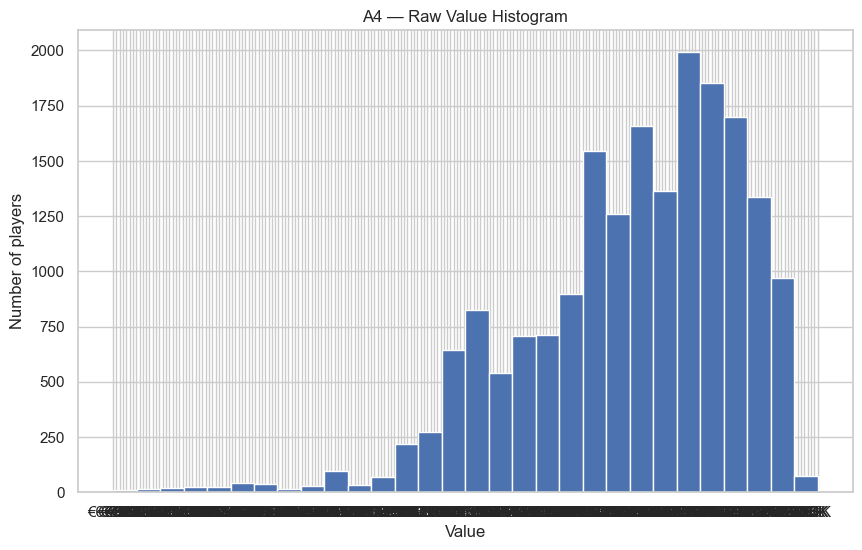

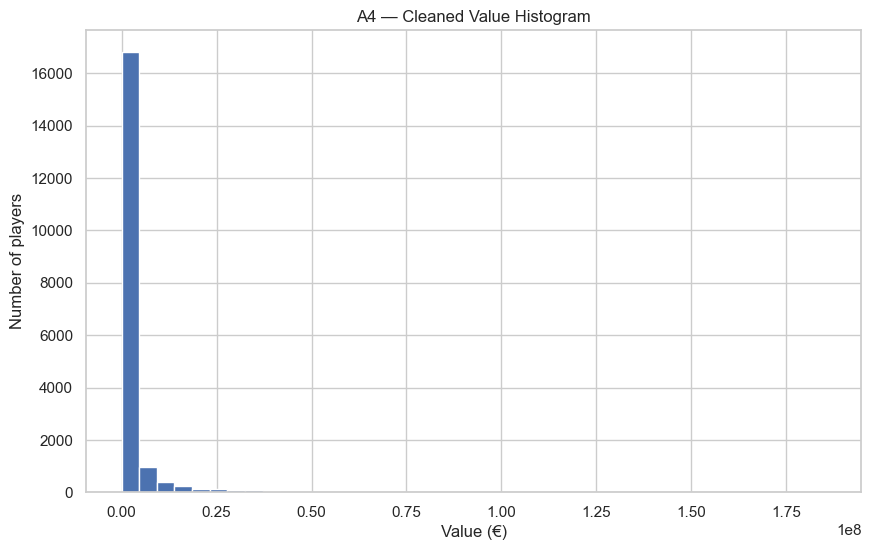

,Observation
0,"The raw Value field is text-formatted, so a nu..."


In [8]:
# A4 — raw Value histogram attempt, then cleaned Value histogram
plt.figure(figsize=(10, 6))
try:
    plt.hist(raw["Value"], bins=30)
    plt.title("A4 — Raw Value Histogram")
    plt.xlabel("Value")
    plt.ylabel("Number of players")
    plt.show()
except Exception as e:
    plt.close()
    print("Raw histogram cannot be meaningfully plotted as numeric data.")
    print("Reason:", type(e).__name__, "-", e)

plt.figure(figsize=(10, 6))
plt.hist(clean["Value"].dropna(), bins=40)
plt.title("A4 — Cleaned Value Histogram")
plt.xlabel("Value (€)")
plt.ylabel("Number of players")
plt.show()

observation("The raw Value field is text-formatted, so a numeric histogram either fails or is meaningless. Cleaning converts it into a numeric field so its distribution can be plotted correctly.")

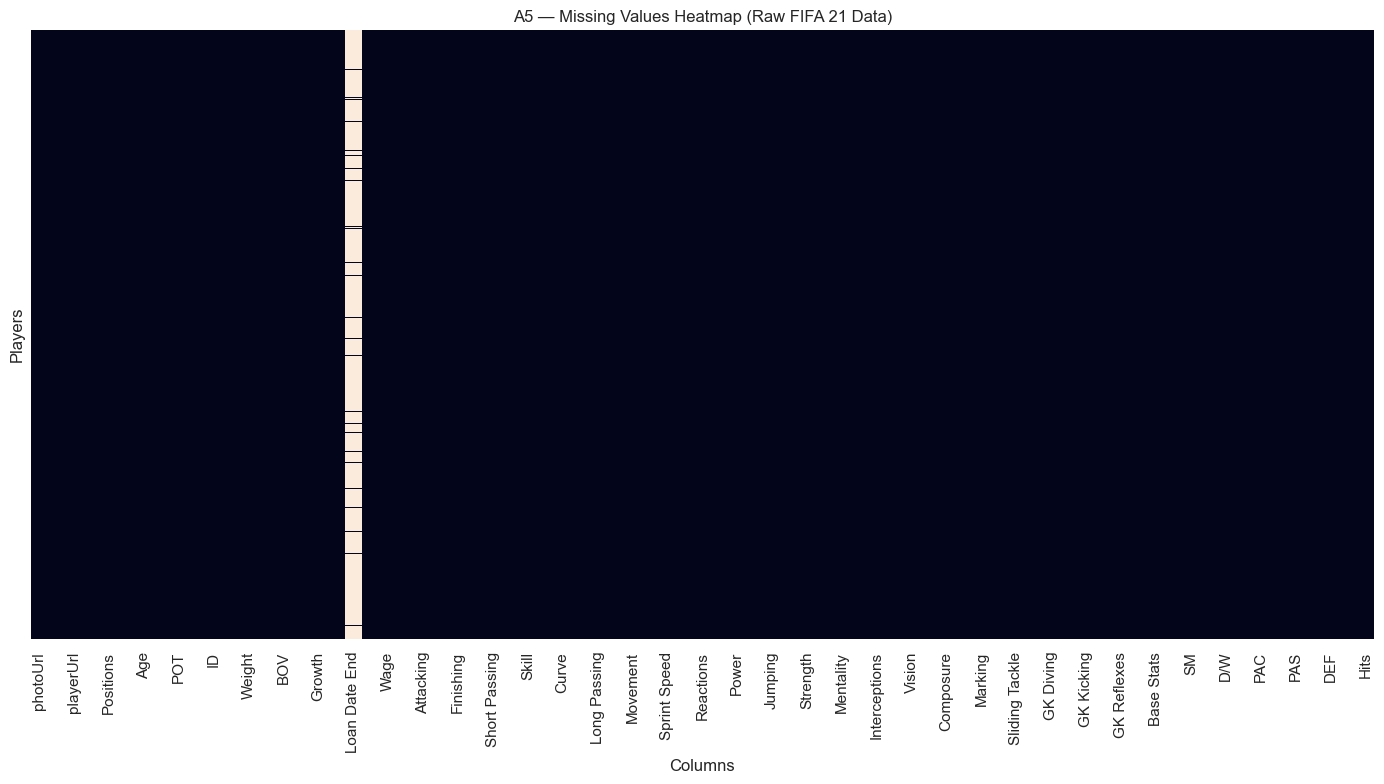

,Observation
0,Missing values are concentrated in 1 columns r...


In [9]:
# A5 — heatmap of missing values in raw data
plt.figure(figsize=(14, 8))
sns.heatmap(raw.isnull(), cbar=False, yticklabels=False)
plt.title("A5 — Missing Values Heatmap (Raw FIFA 21 Data)")
plt.xlabel("Columns")
plt.ylabel("Players")
plt.tight_layout()
plt.show()

missing_cols = raw.columns[raw.isnull().any()].tolist()
observation(f"Missing values are concentrated in {len(missing_cols)} columns rather than appearing equally across every column. Columns with missing values are: {', '.join(missing_cols[:15])}" + (" ..." if len(missing_cols) > 15 else ""))

## Part B — One column at a time
All Part B plots use the cleaned dataset as required by the assignment.

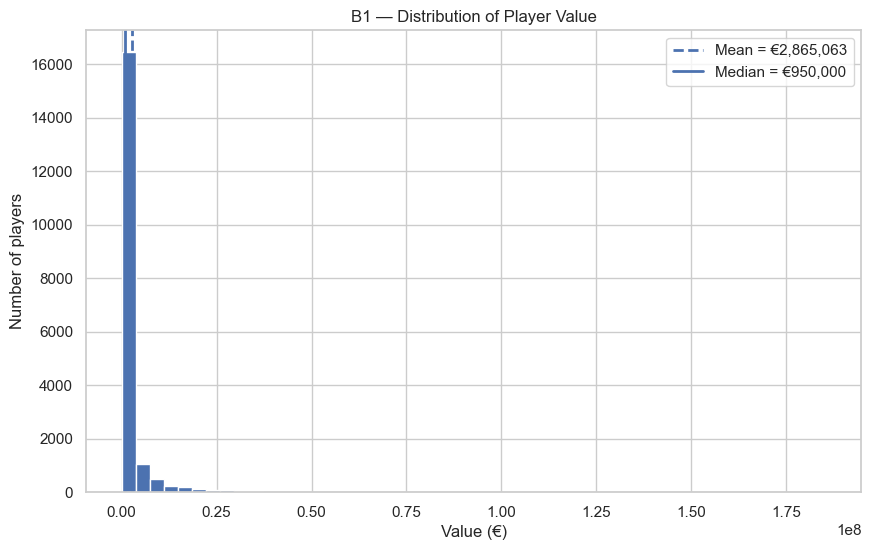

,Observation
0,The Value distribution is right-skewed with a ...


In [10]:
# B1 — Value histogram with mean and median
value = numeric_series(clean, "Value")
mean_value = value.mean()
median_value = value.median()

plt.figure(figsize=(10, 6))
plt.hist(value, bins=50)
plt.axvline(mean_value, linestyle="--", linewidth=2, label=f"Mean = €{mean_value:,.0f}")
plt.axvline(median_value, linestyle="-", linewidth=2, label=f"Median = €{median_value:,.0f}")
plt.title("B1 — Distribution of Player Value")
plt.xlabel("Value (€)")
plt.ylabel("Number of players")
plt.legend()
plt.show()

shape_text = "right-skewed with a long right tail" if mean_value > median_value else "approximately balanced"
observation(f"The Value distribution is {shape_text}. The mean (€{mean_value:,.0f}) is {'above' if mean_value > median_value else 'near/below'} the median (€{median_value:,.0f}), indicating the influence of highly valuable players.")

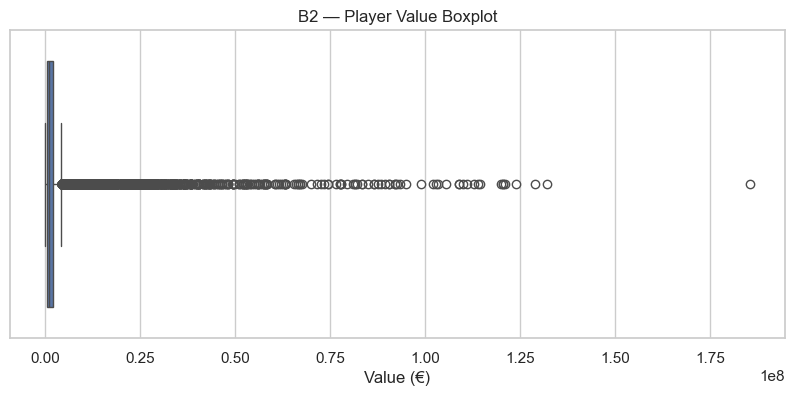

,Observation
0,The boxplot shows 2297 high-value observations...


In [11]:
# B2 — Value boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=value)
plt.title("B2 — Player Value Boxplot")
plt.xlabel("Value (€)")
plt.show()

q1, q3 = value.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outlier_count = int((value > upper_fence).sum())
observation(f"The boxplot shows {outlier_count} high-value observations beyond the usual upper fence. In football terms, these represent players whose transfer values are exceptionally high compared with most players.")

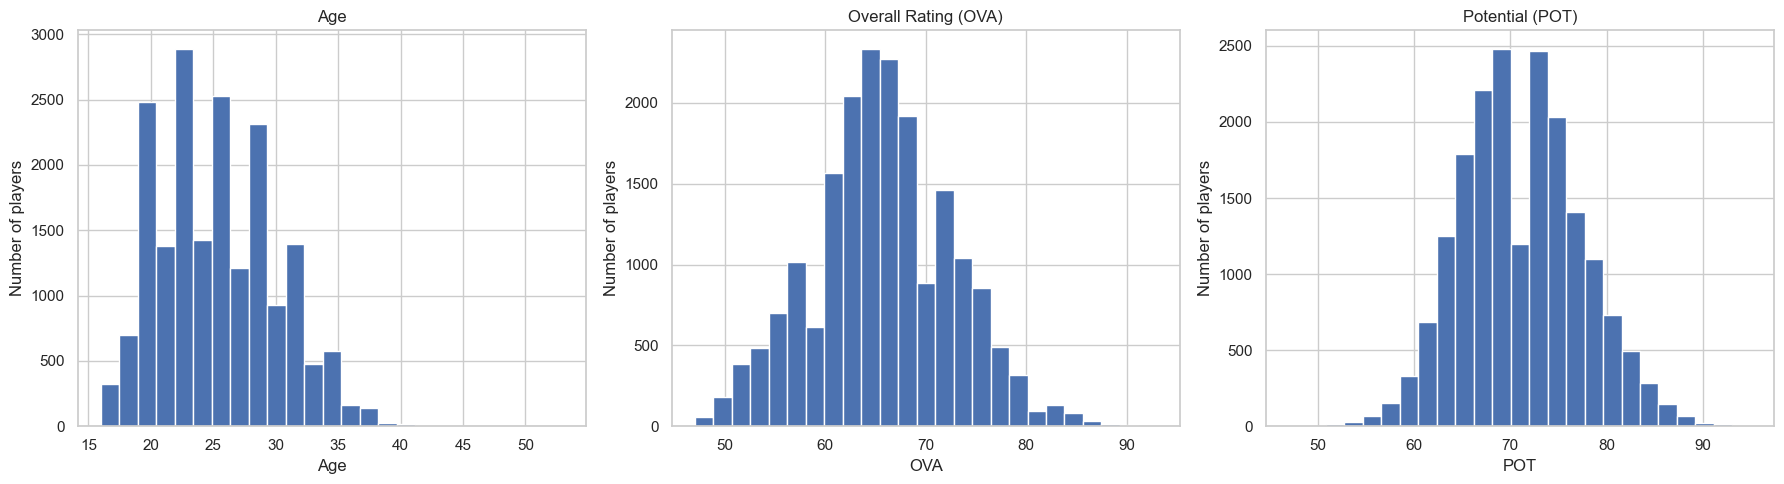

,Observation
0,"Among the three distributions, Age is the clos..."


In [12]:
# B3 — Age, OVA and POT histograms
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(
    axes, ["Age", clean_ova_col, "POT"], ["Age", "Overall Rating (OVA)", "Potential (POT)"]
):
    ax.hist(numeric_series(clean, col), bins=25)
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of players")
plt.tight_layout()
plt.show()

age_mode = clean["Age"].mode().iloc[0]
age_mean = clean["Age"].mean()
observation(f"Among the three distributions, Age is the closest to a conventional bell-shaped distribution. The most common player age is {age_mode} years.")

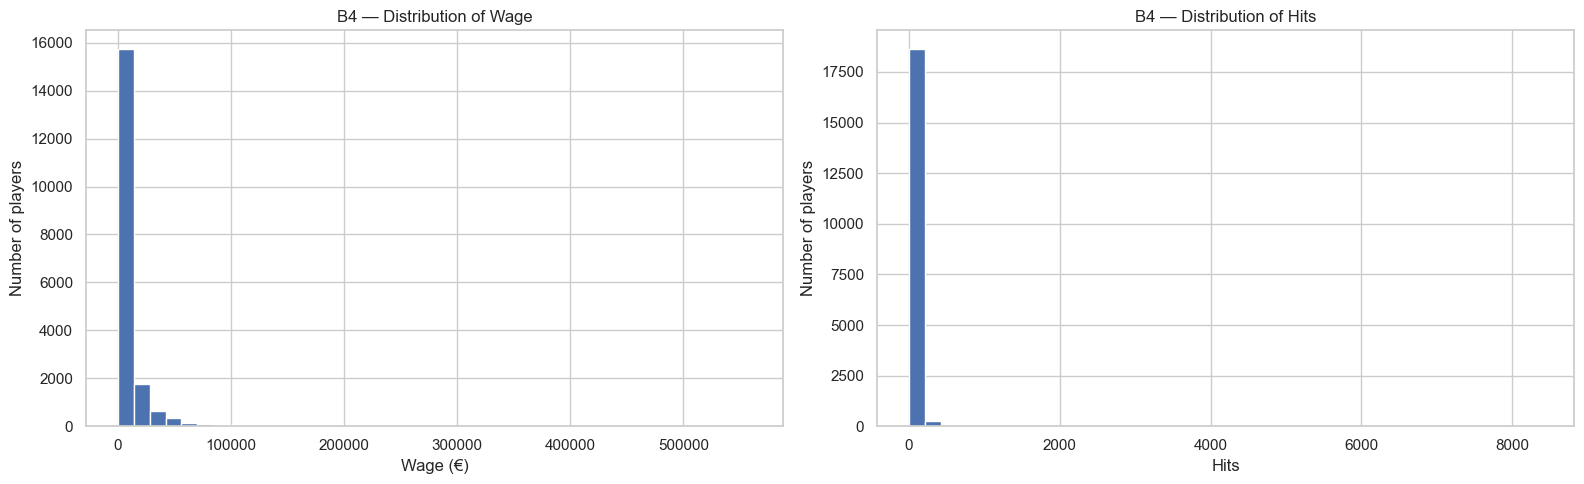

,Observation
0,Wage and Hits are also concentrated toward low...


In [13]:
# B4 — Wage and Hits histograms
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col, label in zip(axes, ["Wage", "Hits"], ["Wage (€)", "Hits"]):
    ax.hist(numeric_series(clean, col), bins=40)
    ax.set_title(f"B4 — Distribution of {col}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of players")
plt.tight_layout()
plt.show()

observation("Wage and Hits are also concentrated toward lower values with a smaller number of very large observations. Their distributions are therefore similarly right-skewed, although the amount of skew differs from Value.")

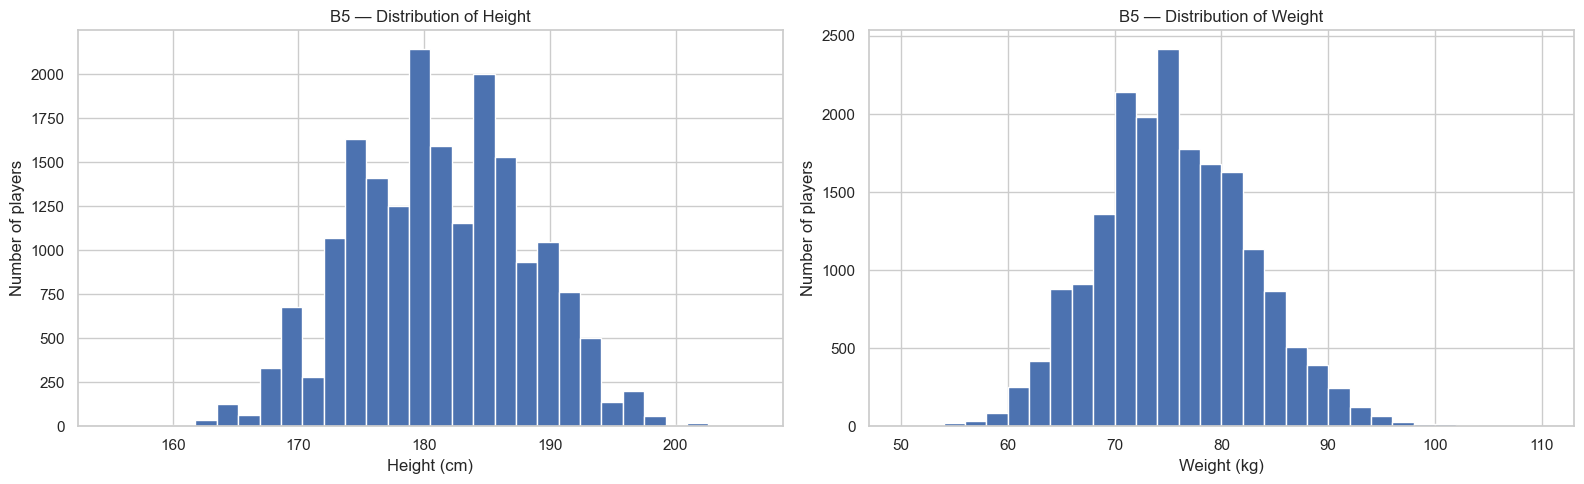

,Observation
0,The typical player is around 181 cm tall and w...


In [14]:
# B5 — Height and Weight histograms
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col, unit in zip(axes, ["Height", "Weight"], ["cm", "kg"]):
    ax.hist(numeric_series(clean, col), bins=30)
    ax.set_title(f"B5 — Distribution of {col}")
    ax.set_xlabel(f"{col} ({unit})")
    ax.set_ylabel("Number of players")
plt.tight_layout()
plt.show()

height_median = numeric_series(clean, "Height").median()
weight_median = numeric_series(clean, "Weight").median()
observation(f"The typical player is around {height_median:.0f} cm tall and weighs about {weight_median:.0f} kg, using the medians as representative values.")

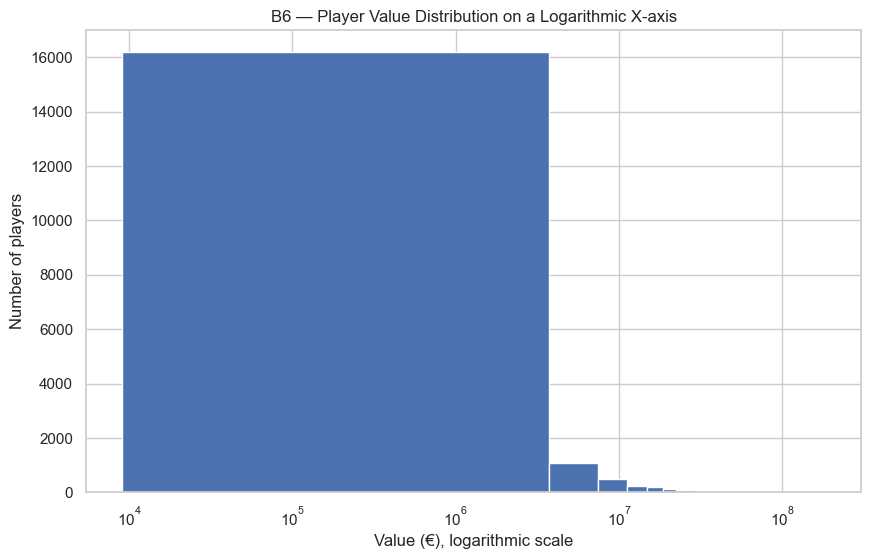

,Observation
0,The logarithmic x-axis spreads out the lower a...


In [15]:
# B6 — Value histogram with logarithmic x-axis
positive_value = value[value > 0]
plt.figure(figsize=(10, 6))
plt.hist(positive_value, bins=50)
plt.xscale("log")
plt.title("B6 — Player Value Distribution on a Logarithmic X-axis")
plt.xlabel("Value (€), logarithmic scale")
plt.ylabel("Number of players")
plt.show()

observation("The logarithmic x-axis spreads out the lower and middle values and makes the high-value tail easier to inspect. The underlying Value data is unchanged; only the axis scale is different.")

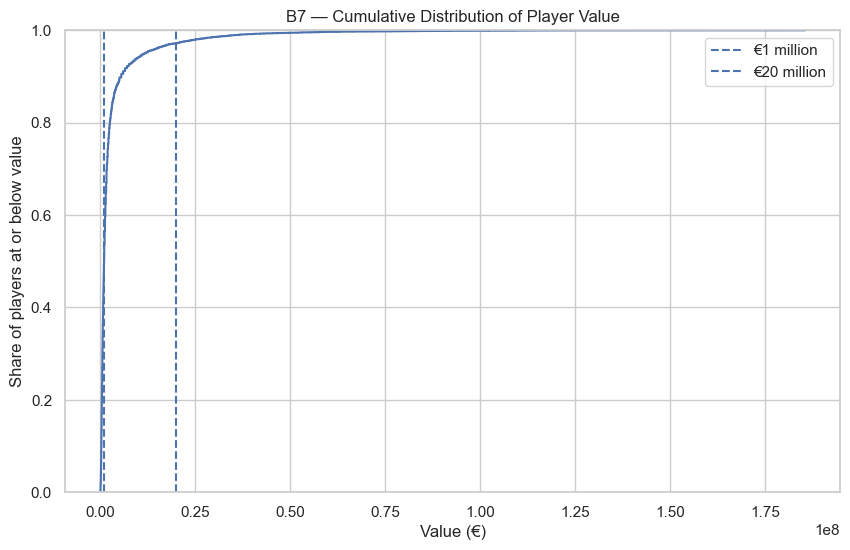

,Observation
0,About 51.0% of players are worth less than €1 ...


In [16]:
# B7 — ECDF of Value
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=clean, x="Value")
plt.axvline(1_000_000, linestyle="--", label="€1 million")
plt.axvline(20_000_000, linestyle="--", label="€20 million")
plt.title("B7 — Cumulative Distribution of Player Value")
plt.xlabel("Value (€)")
plt.ylabel("Share of players at or below value")
plt.legend()
plt.show()

share_less_1m = (value < 1_000_000).mean()
share_more_20m = (value > 20_000_000).mean()
observation(f"About {share_less_1m:.1%} of players are worth less than €1 million, while about {share_more_20m:.1%} are worth more than €20 million.")

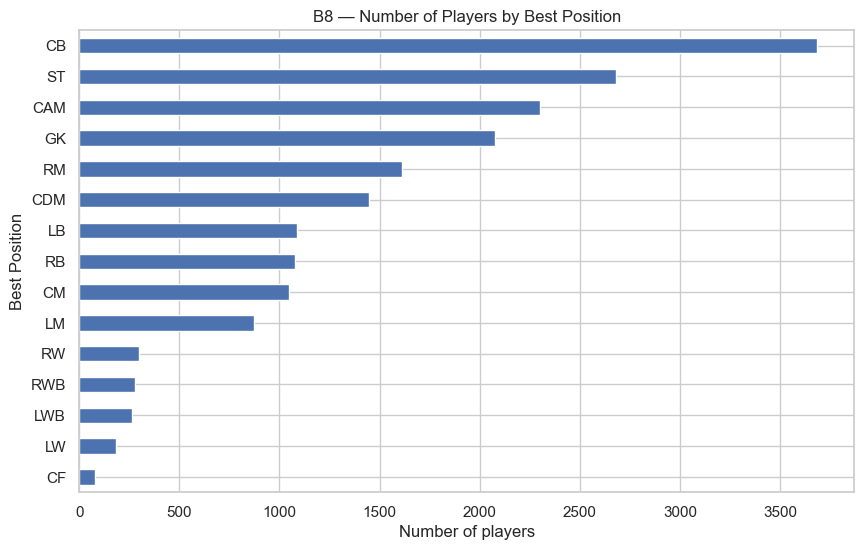

,Observation
0,"The most common position is CB (3686 players),..."


In [17]:
# B8 — number of players by Best Position
pos_counts = clean["Best Position"].value_counts()
plt.figure(figsize=(10, 6))
pos_counts.sort_values(ascending=True).plot.barh()
plt.title("B8 — Number of Players by Best Position")
plt.xlabel("Number of players")
plt.ylabel("Best Position")
plt.show()

observation(f"The most common position is {pos_counts.idxmax()} ({pos_counts.max()} players), while the rarest is {pos_counts.idxmin()} ({pos_counts.min()} players).")

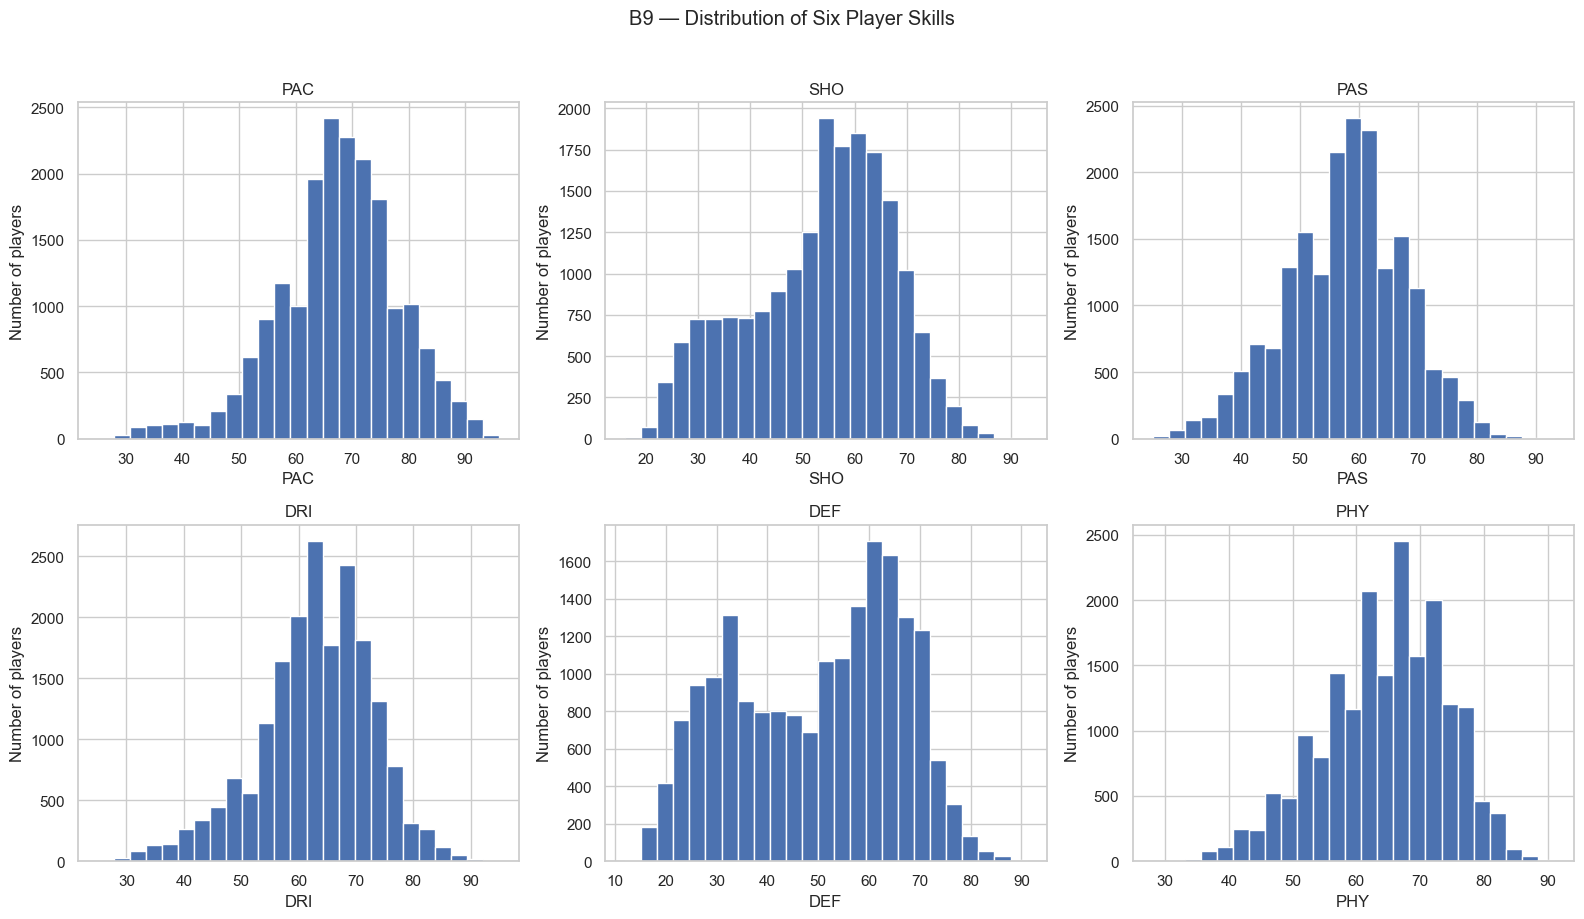

,Observation
0,"Among the six skill distributions, DRI has the..."


In [18]:
# B9 (Extra) — six skill histograms
skill_cols = ["PAC", "SHO", "PAS", "DRI", "DEF", "PHY"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), skill_cols):
    ax.hist(numeric_series(clean, col), bins=25)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of players")
plt.suptitle("B9 — Distribution of Six Player Skills", y=1.02)
plt.tight_layout()
plt.show()

skew_values = {c: numeric_series(clean, c).skew() for c in skill_cols}
most_non_normal = max(skew_values, key=lambda c: abs(skew_values[c]))
observation(f"Among the six skill distributions, {most_non_normal} has the strongest departure from a simple symmetric shape based on skewness. Two peaks, when visible, can reflect different player roles and skill profiles.")

## Part C — Two columns together

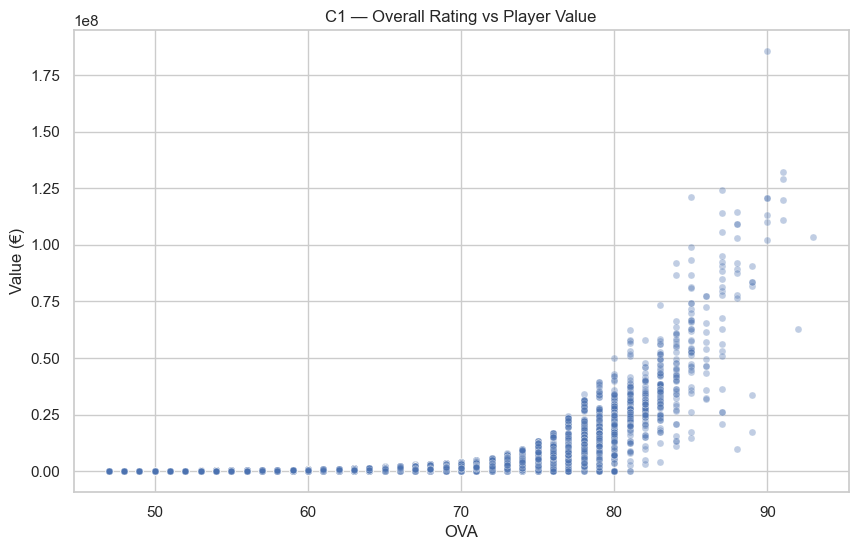

,Observation
0,"Value generally increases as OVA increases, bu..."


In [19]:
# C1 — OVA vs Value
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean, x=clean_ova_col, y="Value", alpha=0.35, s=25)
plt.title("C1 — Overall Rating vs Player Value")
plt.xlabel("OVA")
plt.ylabel("Value (€)")
plt.show()
observation("Value generally increases as OVA increases, but the increase becomes more pronounced among highly rated players. There is still substantial variation at the same OVA.")

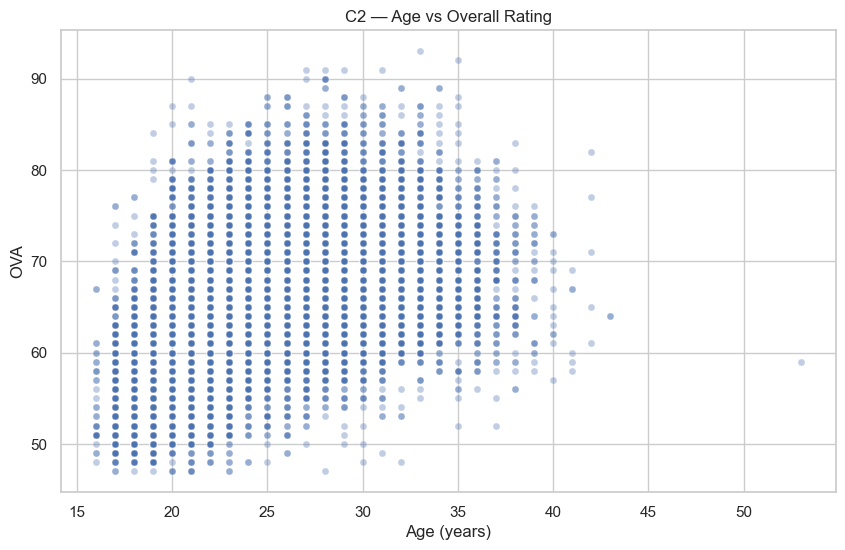

,Observation
0,The average OVA reaches its highest point arou...


In [20]:
# C2 — Age vs OVA
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean, x="Age", y=clean_ova_col, alpha=0.35, s=25)
plt.title("C2 — Age vs Overall Rating")
plt.xlabel("Age (years)")
plt.ylabel("OVA")
plt.show()

age_bins = clean.groupby("Age")[clean_ova_col].mean()
peak_age = age_bins.idxmax()
observation(f"The average OVA reaches its highest point around age {peak_age}. Ratings tend to rise through the development years and then become more variable as players age.")

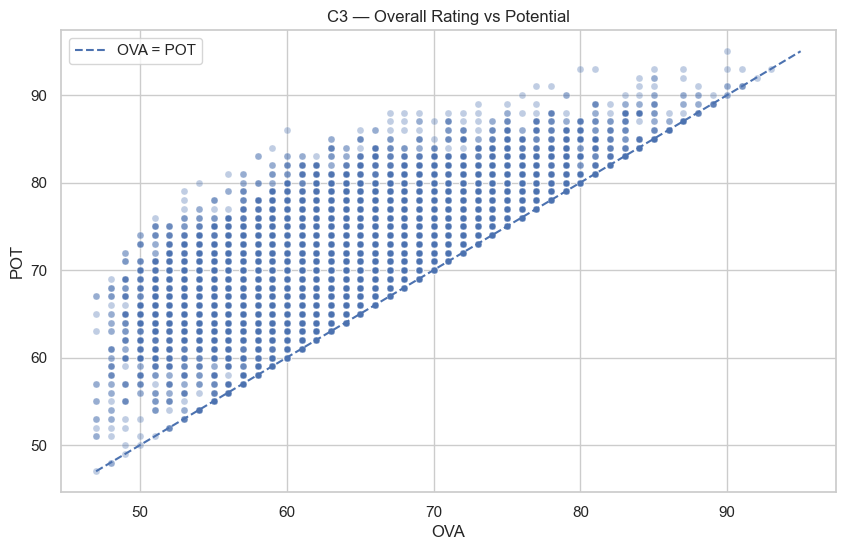

,Name,OVA,POT,_gap
14954,B. Arrey-Mbi,60,86,26
17900,R. Richards,54,80,26
18147,A. Hajdari,53,79,26
15971,C. Riad,59,84,25
16239,O. Babuscu,58,83,25
16387,W. Faghir,58,83,25
17192,D. Leyva,56,81,25
18191,S. Auklend,53,78,25
18673,T. Gulliksen,51,76,25
16996,I. Touré,57,81,24


,Observation
0,Players far above the diagonal have much more ...


In [21]:
# C3 — OVA vs POT with diagonal OVA=POT
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean, x=clean_ova_col, y="POT", alpha=0.35, s=25)
lo = min(clean[clean_ova_col].min(), clean["POT"].min())
hi = max(clean[clean_ova_col].max(), clean["POT"].max())
plt.plot([lo, hi], [lo, hi], linestyle="--", label="OVA = POT")
plt.title("C3 — Overall Rating vs Potential")
plt.xlabel("OVA")
plt.ylabel("POT")
plt.legend()
plt.show()

gap = clean["POT"] - clean[clean_ova_col]
top_future = clean.assign(_gap=gap).nlargest(10, "_gap")
display(top_future[["Name", clean_ova_col, "POT", "_gap"]])
observation("Players far above the diagonal have much more potential than their current rating. These are generally younger players with room for development.")

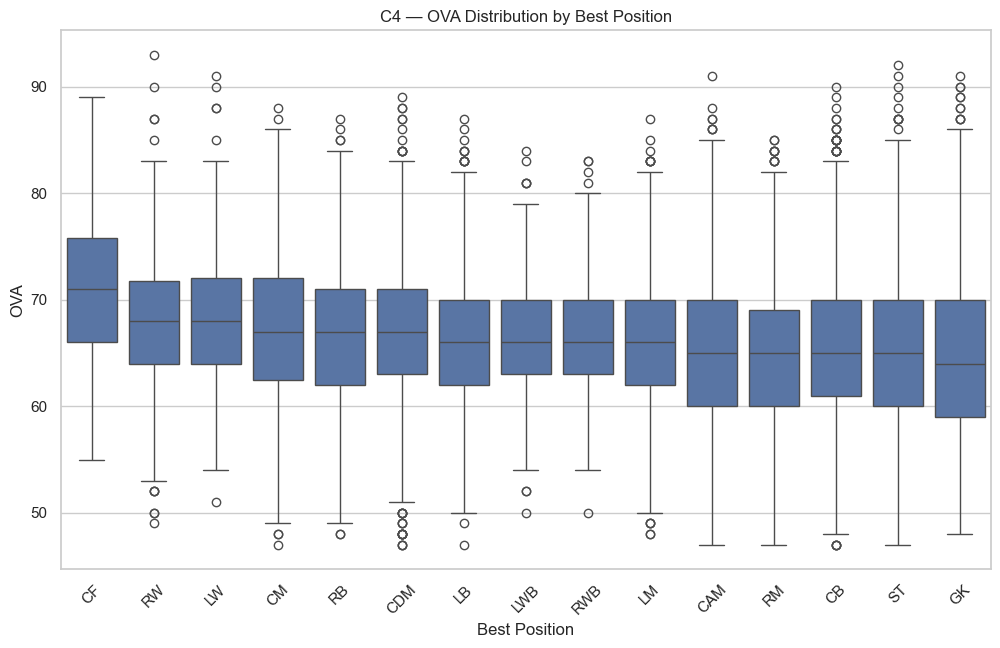

,Observation
0,"Top 3 positions by median OVA: CF, RW, LW. Bot..."


In [22]:
# C4 — OVA by Best Position, ordered by median
position_median = clean.groupby("Best Position")[clean_ova_col].median().sort_values(ascending=False)
ordered_positions = position_median.index.tolist()

plt.figure(figsize=(12, 7))
sns.boxplot(data=clean, x="Best Position", y=clean_ova_col, order=ordered_positions)
plt.title("C4 — OVA Distribution by Best Position")
plt.xlabel("Best Position")
plt.ylabel("OVA")
plt.xticks(rotation=45)
plt.show()

observation(f"Top 3 positions by median OVA: {', '.join(position_median.head(3).index)}. Bottom 3: {', '.join(position_median.tail(3).index)}.")

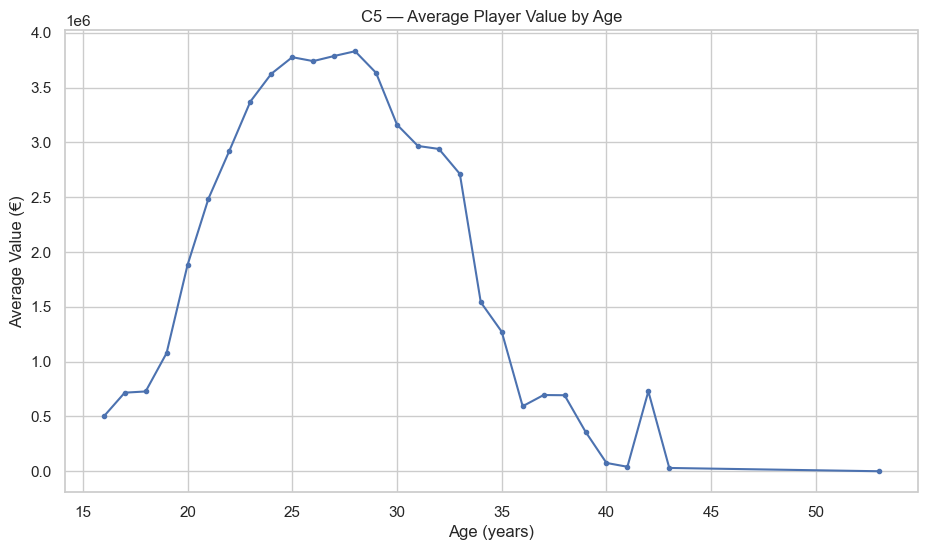

,Observation
0,"The highest average Value occurs at age 28, wh..."


In [23]:
# C5 — Average Value by Age
avg_value_age = clean.groupby("Age")["Value"].mean()
plt.figure(figsize=(11, 6))
plt.plot(avg_value_age.index, avg_value_age.values, marker="o", markersize=3)
plt.title("C5 — Average Player Value by Age")
plt.xlabel("Age (years)")
plt.ylabel("Average Value (€)")
plt.show()

best_value_age = avg_value_age.idxmax()
observation(f"The highest average Value occurs at age {best_value_age}, where the mean player value is about €{avg_value_age.max():,.0f}.")

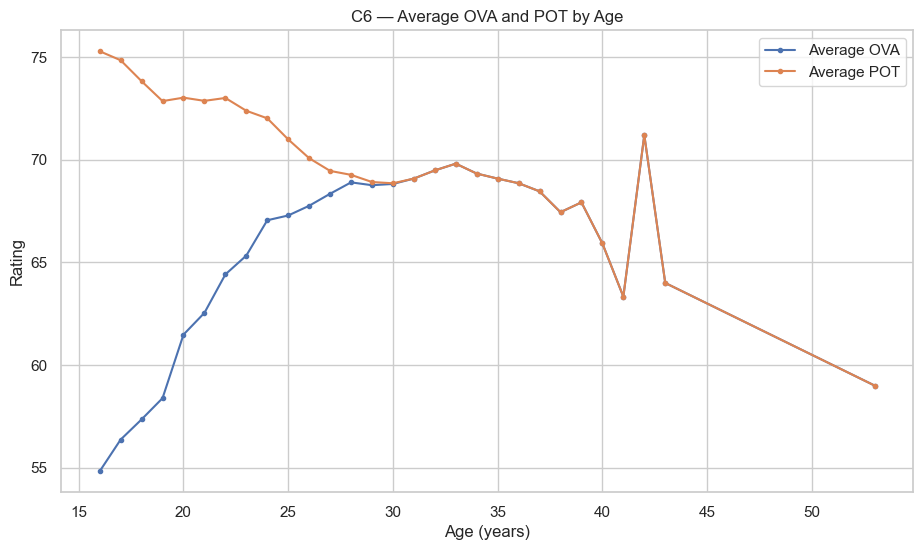

,Observation
0,The two lines are farthest apart around ages [...


In [24]:
# C6 — Average OVA and POT by Age
avg_ratings_age = clean.groupby("Age")[[clean_ova_col, "POT"]].mean()
plt.figure(figsize=(11, 6))
plt.plot(avg_ratings_age.index, avg_ratings_age[clean_ova_col], marker="o", markersize=3, label="Average OVA")
plt.plot(avg_ratings_age.index, avg_ratings_age["POT"], marker="o", markersize=3, label="Average POT")
plt.title("C6 — Average OVA and POT by Age")
plt.xlabel("Age (years)")
plt.ylabel("Rating")
plt.legend()
plt.show()

gap_age = (avg_ratings_age["POT"] - avg_ratings_age[clean_ova_col]).abs()
far_age = gap_age.nlargest(3).index.tolist()
near_age = gap_age.nsmallest(3).index.tolist()
observation(f"The two lines are farthest apart around ages {far_age} and closest around ages {near_age}. The gap represents how much future potential exceeds current average rating.")

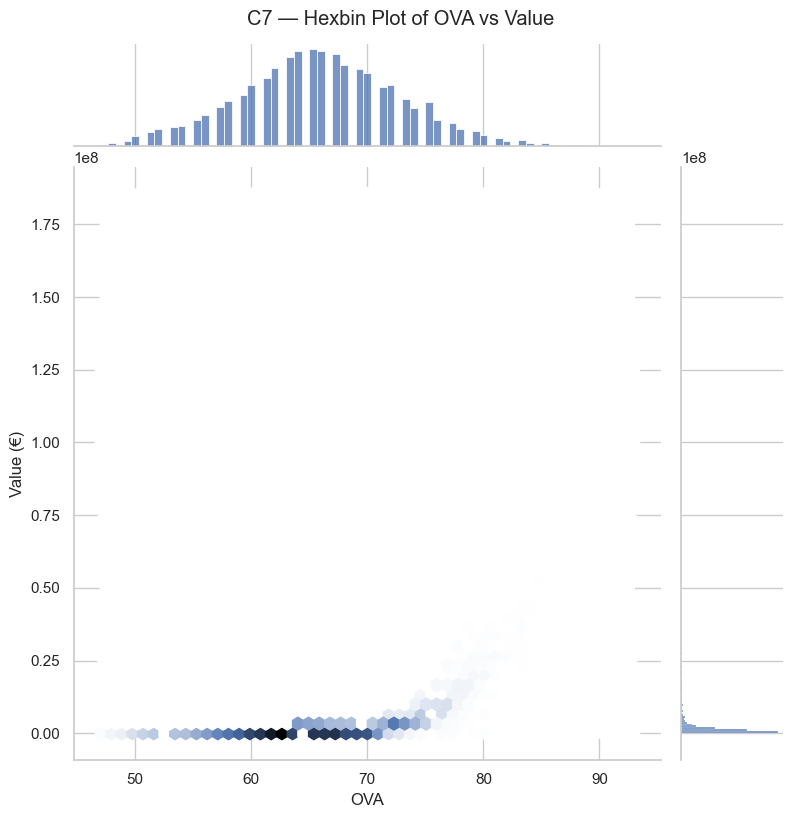

,Observation
0,The densest region is concentrated around the ...


In [25]:
# C7 — Hexbin / joint plot of OVA vs Value
g = sns.jointplot(data=clean, x=clean_ova_col, y="Value", kind="hex", height=8)
g.set_axis_labels("OVA", "Value (€)")
g.fig.suptitle("C7 — Hexbin Plot of OVA vs Value", y=1.02)
plt.show()

observation("The densest region is concentrated around the middle-to-lower OVA range and relatively low player values, where the majority of players are packed together.")

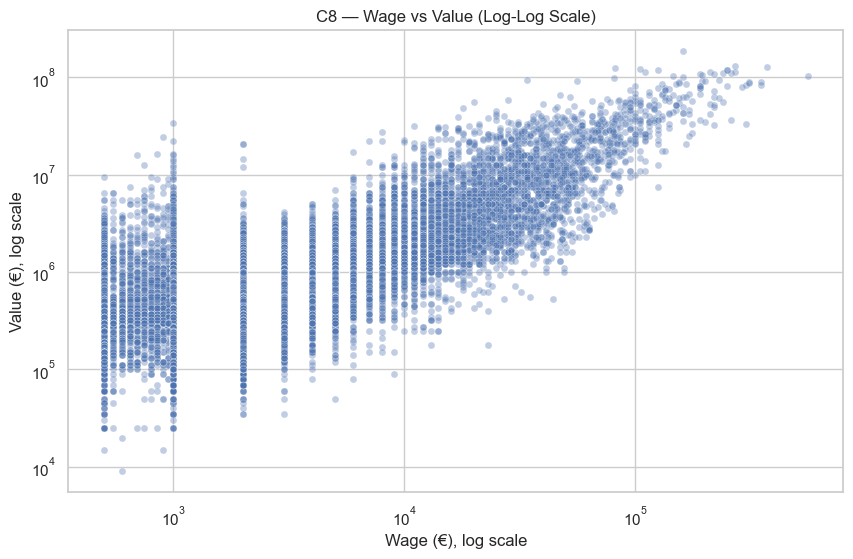

,Observation
0,Wage and Value show a clear positive relations...


In [26]:
# C8 — Wage vs Value on logarithmic axes
c8 = clean[(clean["Wage"] > 0) & (clean["Value"] > 0)]
plt.figure(figsize=(10, 6))
sns.scatterplot(data=c8, x="Wage", y="Value", alpha=0.35, s=25)
plt.xscale("log")
plt.yscale("log")
plt.title("C8 — Wage vs Value (Log-Log Scale)")
plt.xlabel("Wage (€), log scale")
plt.ylabel("Value (€), log scale")
plt.show()

corr_wage_value = np.log(c8[["Wage", "Value"]]).corr().loc["Wage", "Value"]
observation(f"Wage and Value show a clear positive relationship on the log-log plot (correlation of log-transformed values ≈ {corr_wage_value:.2f}), although the points do not form a perfect line.")

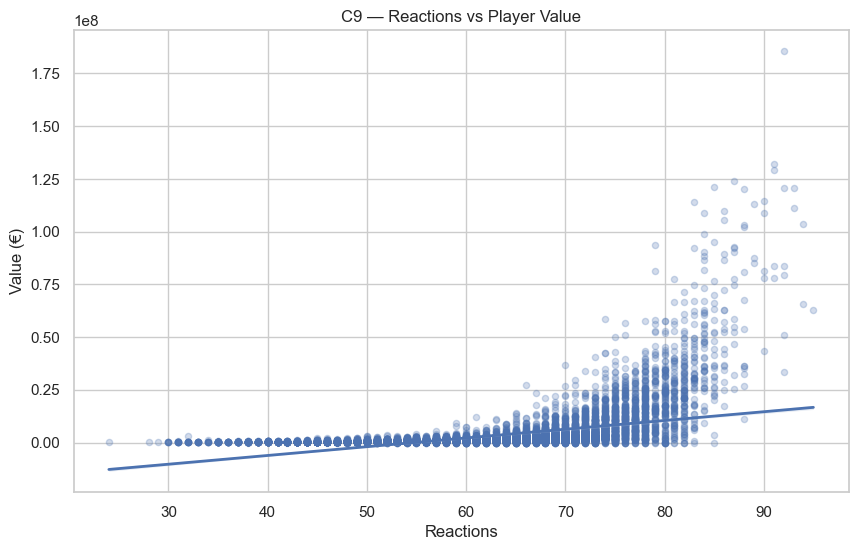

,Observation
0,"The fitted line shows a positive relationship,..."


In [27]:
# C9 — Reactions vs Value regression
plt.figure(figsize=(10, 6))
sns.regplot(data=clean, x="Reactions", y="Value",
            scatter_kws={"alpha": 0.25, "s": 20},
            line_kws={"linewidth": 2})
plt.title("C9 — Reactions vs Player Value")
plt.xlabel("Reactions")
plt.ylabel("Value (€)")
plt.show()

observation("The fitted line shows a positive relationship, but the large spread of points around the line means Reactions alone is not a complete description of player Value.")

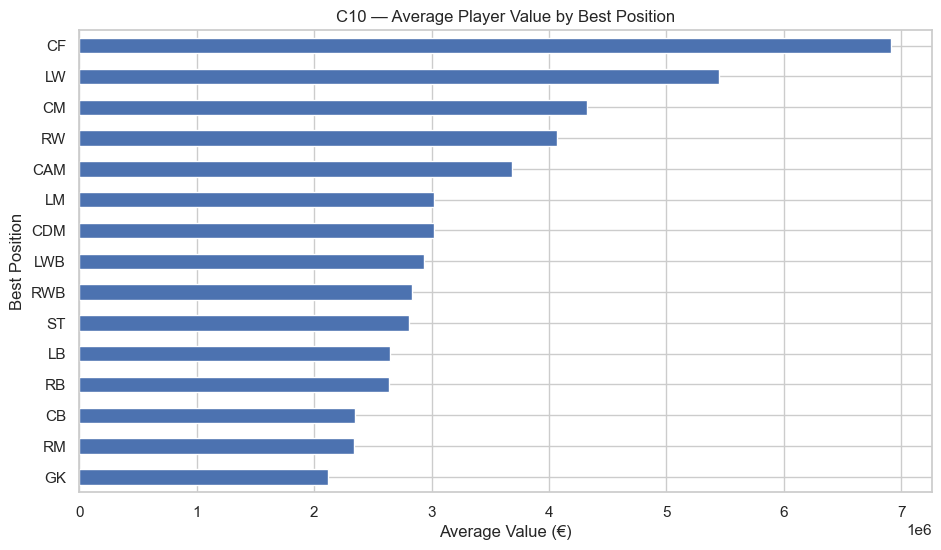

,Observation
0,The positions with the highest average Value a...


In [28]:
# C10 — Average Value by Best Position
avg_position_value = clean.groupby("Best Position")["Value"].mean().sort_values(ascending=False)
plt.figure(figsize=(11, 6))
avg_position_value.sort_values().plot.barh()
plt.title("C10 — Average Player Value by Best Position")
plt.xlabel("Average Value (€)")
plt.ylabel("Best Position")
plt.show()

observation(f"The positions with the highest average Value are {', '.join(avg_position_value.head(3).index)}.")

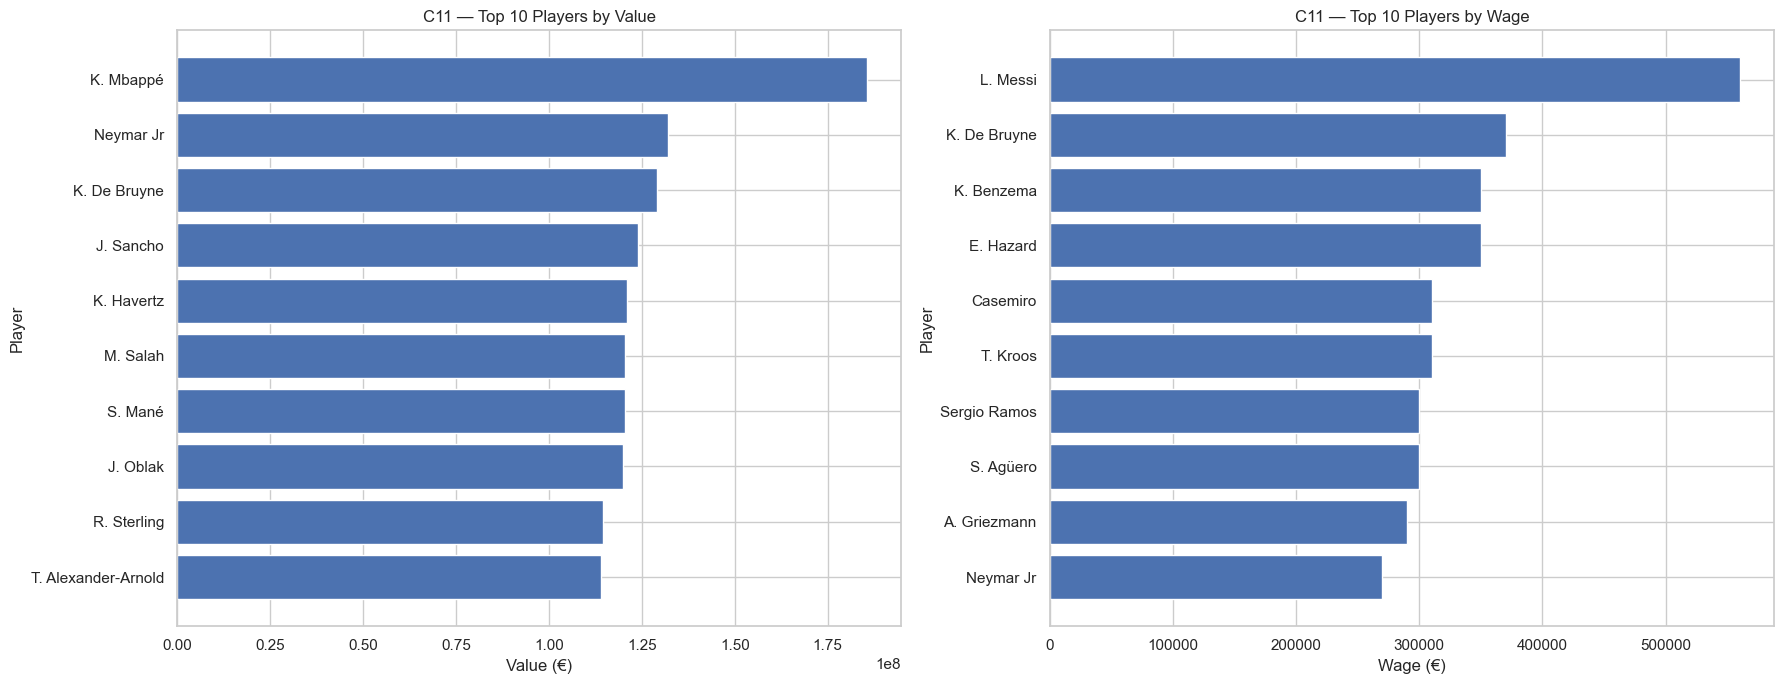

Players appearing in both top-10 lists: ['K. De Bruyne', 'Neymar Jr']


,Observation
0,2 players appear in both top-10 lists: K. De B...


In [29]:
# C11 — Top 10 players by Value and Wage
top_value = clean.nlargest(10, "Value")
top_wage = clean.nlargest(10, "Wage")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].barh(top_value["Name"].iloc[::-1], top_value["Value"].iloc[::-1])
axes[0].set_title("C11 — Top 10 Players by Value")
axes[0].set_xlabel("Value (€)")
axes[0].set_ylabel("Player")

axes[1].barh(top_wage["Name"].iloc[::-1], top_wage["Wage"].iloc[::-1])
axes[1].set_title("C11 — Top 10 Players by Wage")
axes[1].set_xlabel("Wage (€)")
axes[1].set_ylabel("Player")
plt.tight_layout()
plt.show()

both = sorted(set(top_value["Name"]) & set(top_wage["Name"]))
print("Players appearing in both top-10 lists:", both)
observation(f"{len(both)} players appear in both top-10 lists: {', '.join(both) if both else 'none'}.")

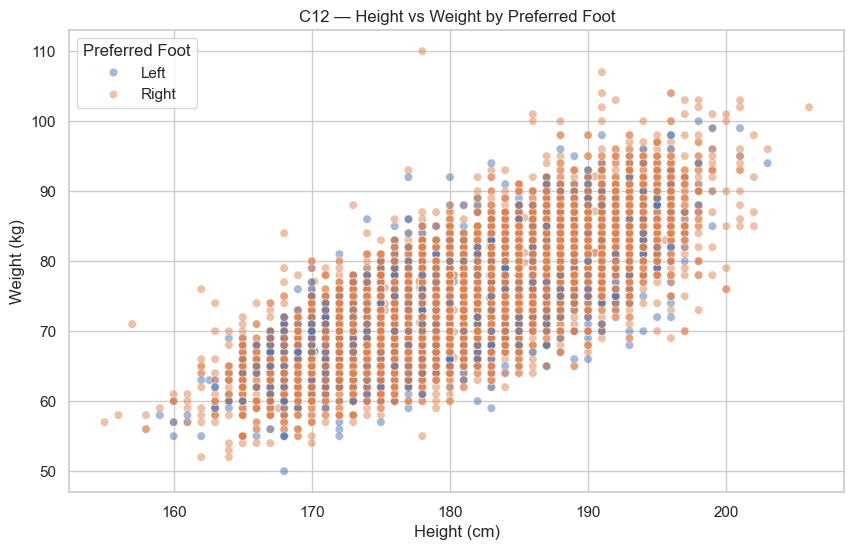

,Observation
0,"The two preferred-foot groups overlap heavily,..."


In [30]:
# C12 (Extra) — Height vs Weight by Preferred Foot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean, x="Height", y="Weight", hue="Preferred Foot", alpha=0.5)
plt.title("C12 — Height vs Weight by Preferred Foot")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.legend(title="Preferred Foot")
plt.show()
observation("The two preferred-foot groups overlap heavily, so preferred foot does not visibly separate players into distinct height-weight groups.")

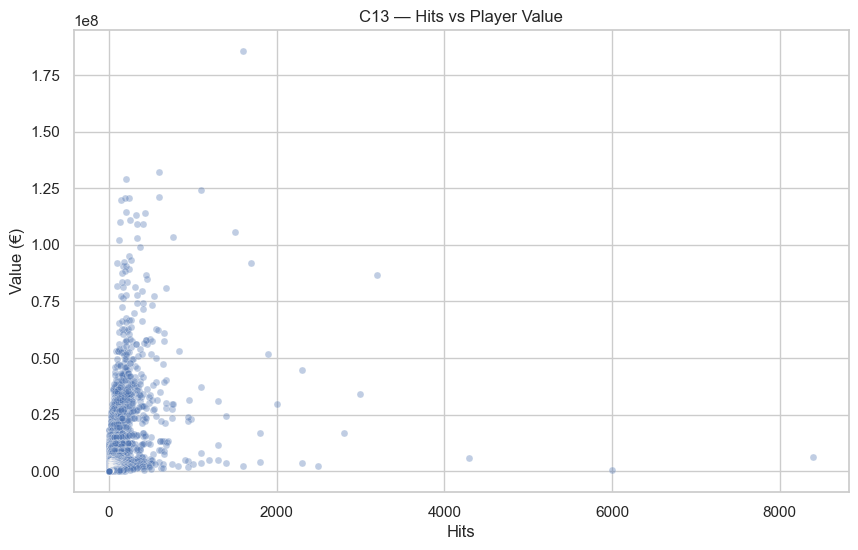

,Observation
0,This plot was chosen because Hits is a popular...


In [31]:
# C13 (Extra) — Free choice: Hits vs Value
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean, x="Hits", y="Value", alpha=0.35, s=25)
plt.title("C13 — Hits vs Player Value")
plt.xlabel("Hits")
plt.ylabel("Value (€)")
plt.show()
observation("This plot was chosen because Hits is a popularity/interest measure that can be compared with player Value. The relationship is positive for some players but has substantial variation.")

## Part D — Many columns together

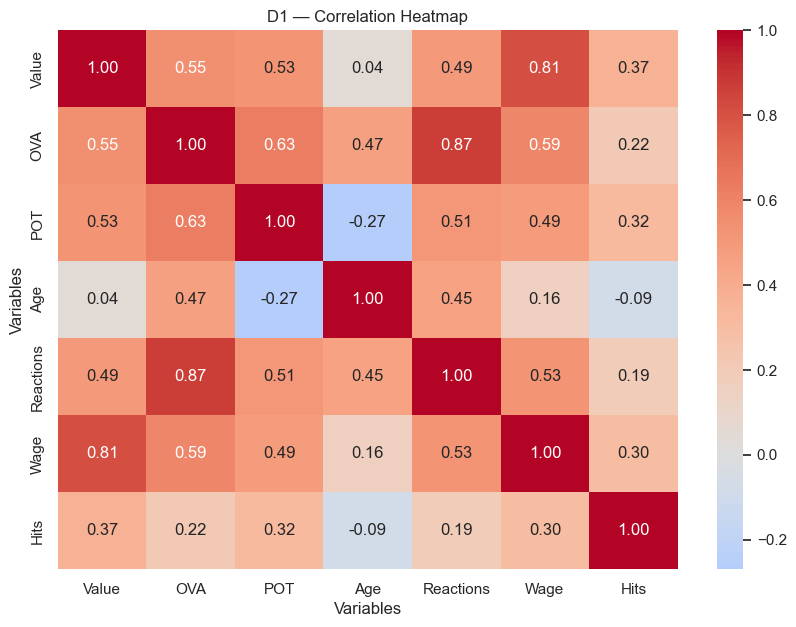

,Observation
0,Strongest relation with Value: Wage (r=0.81). ...


In [32]:
# D1 — correlation heatmap for Value, OVA, POT, Age, Reactions, Wage and Hits
d1_cols = ["Value", clean_ova_col, "POT", "Age", "Reactions", "Wage", "Hits"]
d1_corr = clean[d1_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(d1_corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("D1 — Correlation Heatmap")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.show()

value_corr = d1_corr["Value"].drop("Value").sort_values()
observation(f"Strongest relation with Value: {value_corr.index[-1]} (r={value_corr.iloc[-1]:.2f}). Weakest relation: {value_corr.index[0]} (r={value_corr.iloc[0]:.2f}).")

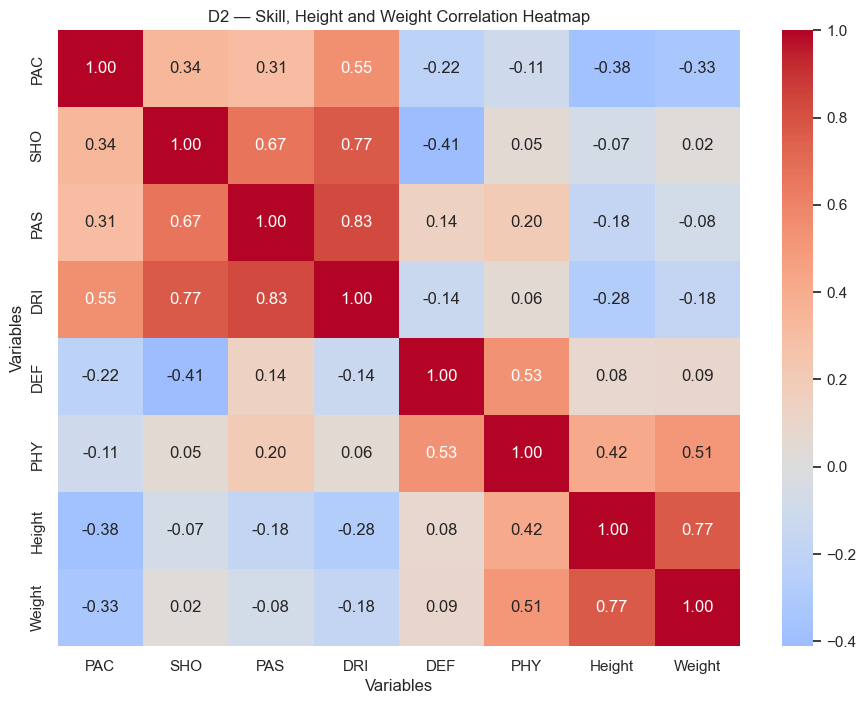

,Observation
0,"A strongly related pair is ('PAS', 'DRI') (r=0..."


In [33]:
# D2 — skills, Height and Weight
d2_cols = ["PAC", "SHO", "PAS", "DRI", "DEF", "PHY", "Height", "Weight"]
d2_corr = clean[d2_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(d2_corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("D2 — Skill, Height and Weight Correlation Heatmap")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.show()

pairs = d2_corr.where(np.triu(np.ones(d2_corr.shape), k=1).astype(bool)).stack().sort_values()
negative_pair = pairs.index[0]
strongest_pair = pairs.abs().sort_values(ascending=False).index[0]
observation(f"A strongly related pair is {strongest_pair} (r={d2_corr.loc[strongest_pair[0], strongest_pair[1]]:.2f}). A negatively related pair is {negative_pair} (r={d2_corr.loc[negative_pair[0], negative_pair[1]]:.2f}).")

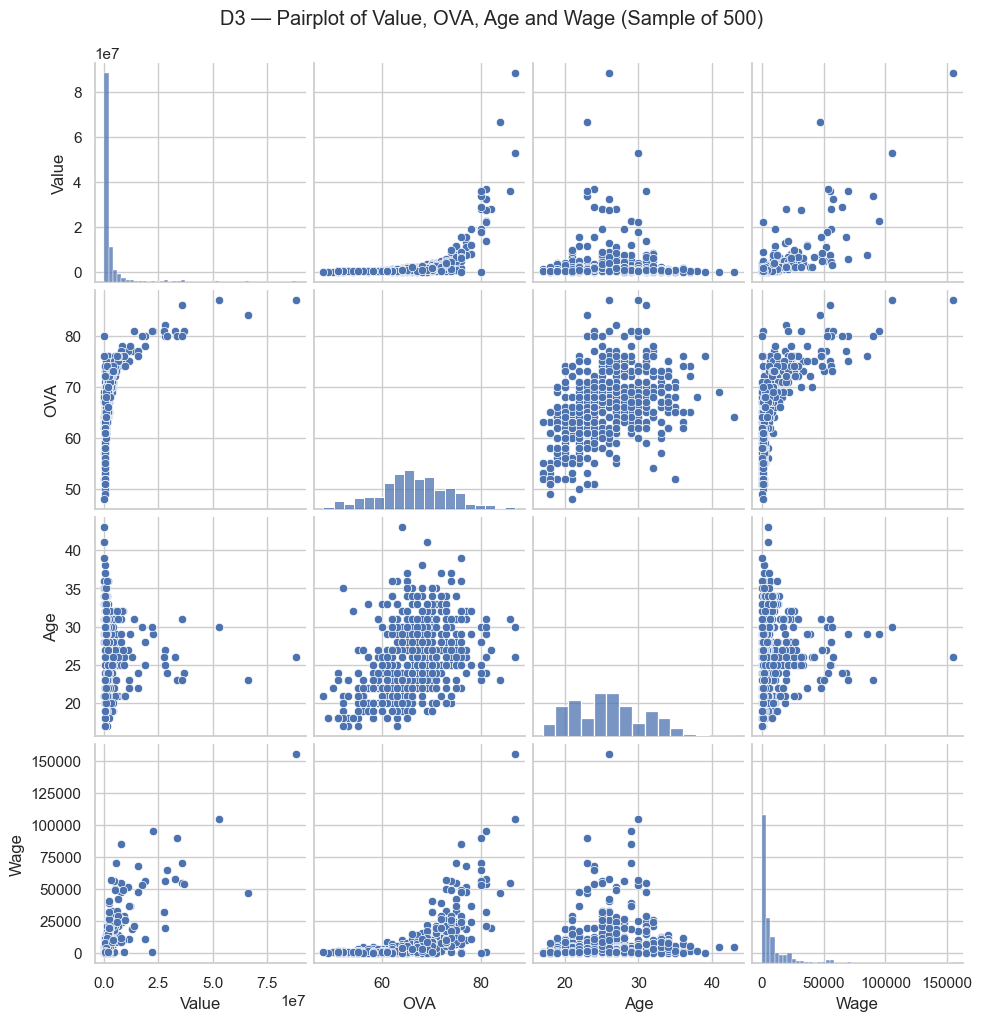

,Observation
0,"The pairplot shows that Value, Wage and OVA ge..."


In [34]:
# D3 — pairplot using a sample of 500 players
pair_cols = ["Value", clean_ova_col, "Age", "Wage"]
sample500 = clean[pair_cols].dropna().sample(n=min(500, len(clean[pair_cols].dropna())), random_state=42)

g = sns.pairplot(sample500)
g.fig.suptitle("D3 — Pairplot of Value, OVA, Age and Wage (Sample of 500)", y=1.02)
plt.show()

observation("The pairplot shows that Value, Wage and OVA generally move together positively, while Age has a weaker and more non-linear relationship with these variables.")

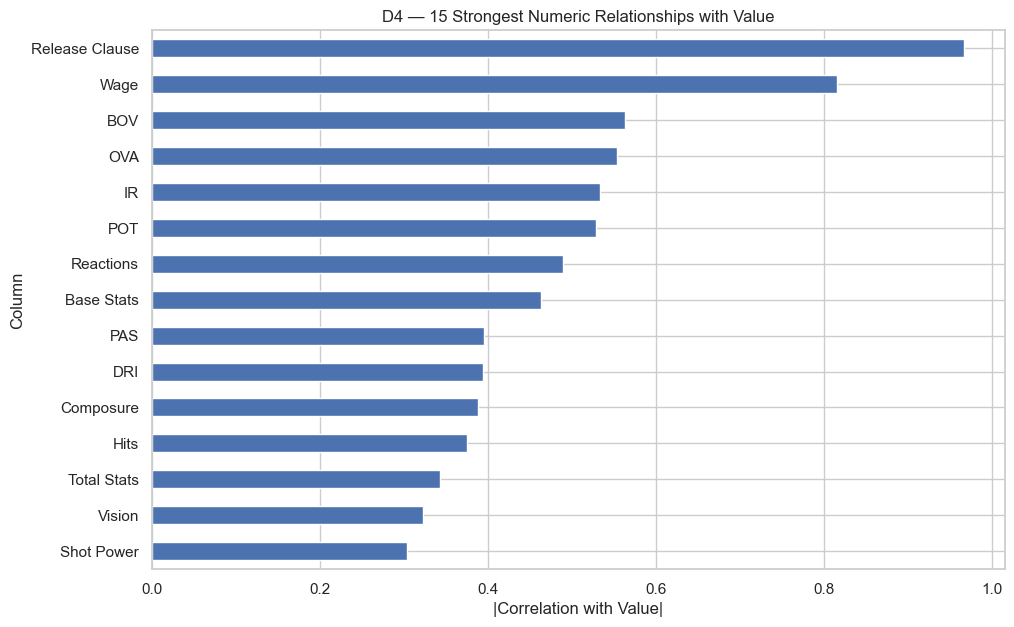

,Absolute correlation,Signed correlation
Release Clause,0.966440,0.966440
Wage,0.814870,0.814870
BOV,0.563253,0.563253
OVA,0.552893,0.552893
IR,0.533569,0.533569
POT,0.528200,0.528200
Reactions,0.489513,0.489513
Base Stats,0.462458,0.462458
PAS,0.394543,0.394543
DRI,0.393347,0.393347


,Observation
0,The strongest numeric relationships with Value...


In [35]:
# D4 — 15 columns most strongly related to Value
numeric_clean = clean.select_dtypes(include=np.number)
corr_to_value = numeric_clean.corr()["Value"].drop("Value").abs().sort_values(ascending=False).head(15)
signed_corr = numeric_clean.corr()["Value"].loc[corr_to_value.index].sort_values()

plt.figure(figsize=(11, 7))
corr_to_value.sort_values().plot.barh()
plt.title("D4 — 15 Strongest Numeric Relationships with Value")
plt.xlabel("|Correlation with Value|")
plt.ylabel("Column")
plt.show()

display(pd.DataFrame({
    "Absolute correlation": corr_to_value,
    "Signed correlation": numeric_clean.corr()["Value"].loc[corr_to_value.index]
}).sort_values("Absolute correlation", ascending=False))

observation(f"The strongest numeric relationships with Value are led by: {', '.join(corr_to_value.head(5).index)}. These include important player performance and market-related variables.")

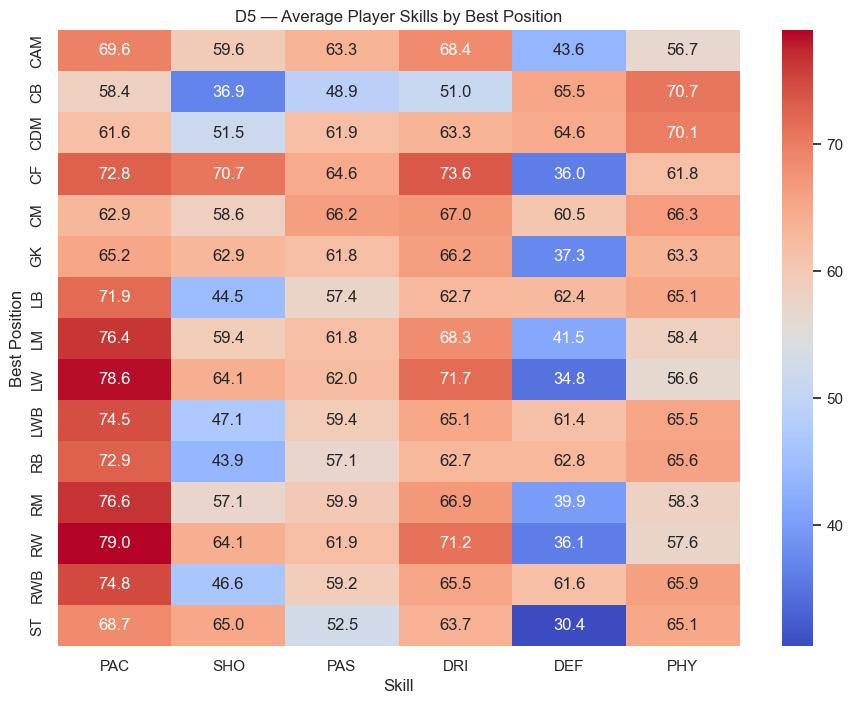

,Position with highest average
PAC,RW
SHO,CF
PAS,CM
DRI,CF
DEF,CB
PHY,CB


,Observation
0,Different positions specialize in different ra...


In [36]:
# D5 — average PAC, SHO, PAS, DRI, DEF, PHY for each Best Position
skill_position = clean.groupby("Best Position")[skill_cols].mean()

plt.figure(figsize=(11, 8))
sns.heatmap(skill_position, annot=True, cmap="coolwarm", fmt=".1f")
plt.title("D5 — Average Player Skills by Best Position")
plt.xlabel("Skill")
plt.ylabel("Best Position")
plt.show()

strongest_position_by_skill = skill_position.idxmax()
display(strongest_position_by_skill.to_frame("Position with highest average"))
observation("Different positions specialize in different ratings: attacking positions tend to lead attacking skills, while defensive positions tend to lead DEF. The heatmap makes these positional strengths visible.")

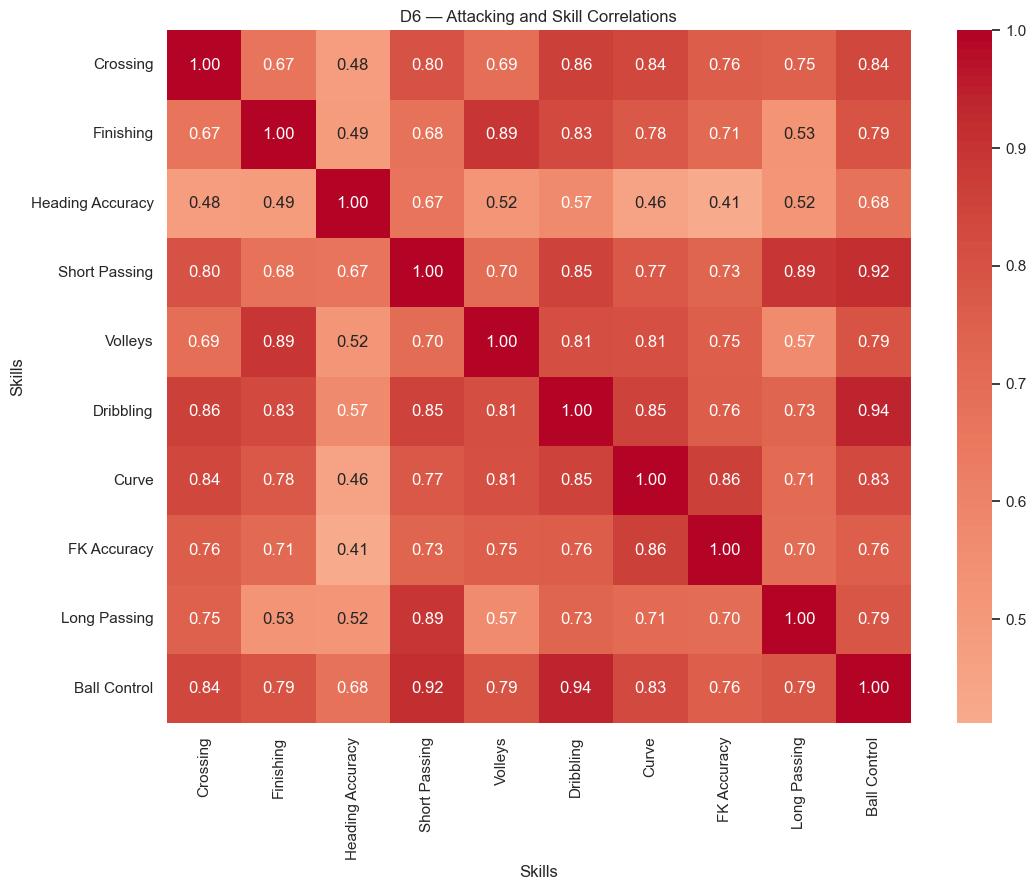

,Observation
0,The attacking/skill columns that move together...


In [37]:
# D6 — attacking and skill correlation heatmap
attack_skill_cols = [
    "Crossing", "Finishing", "Heading Accuracy", "Short Passing",
    "Volleys", "Dribbling", "Curve", "FK Accuracy",
    "Long Passing", "Ball Control"
]
d6_corr = clean[attack_skill_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(d6_corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("D6 — Attacking and Skill Correlations")
plt.xlabel("Skills")
plt.ylabel("Skills")
plt.show()

upper = d6_corr.where(np.triu(np.ones(d6_corr.shape), k=1).astype(bool))
top_pairs = upper.stack().sort_values(ascending=False).head(5)
observation(f"The attacking/skill columns that move together most strongly include {top_pairs.index[0][0]} and {top_pairs.index[0][1]} (r={top_pairs.iloc[0]:.2f}). Passing, ball control and dribbling-related skills show several strong positive relationships.")

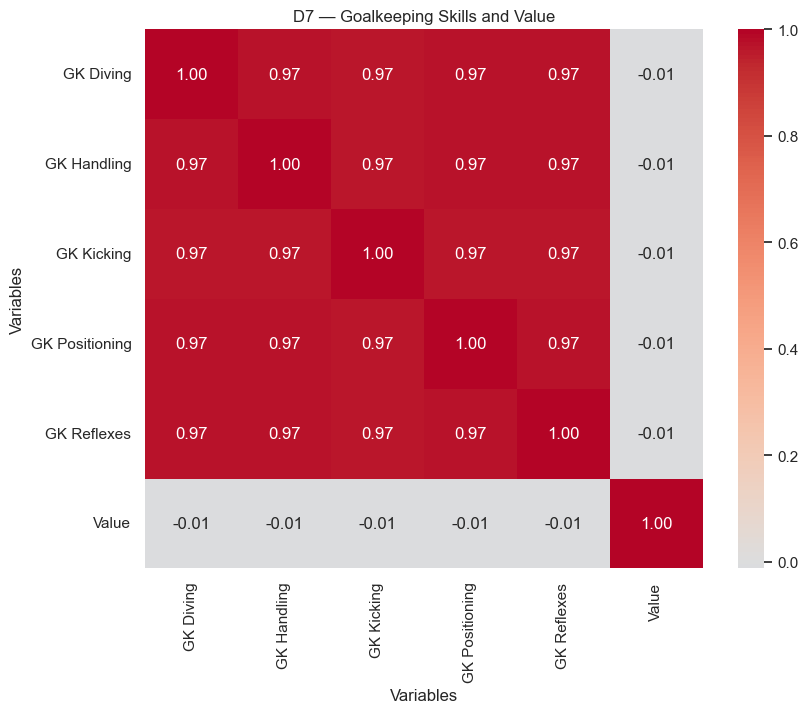

,Observation
0,Goalkeeping skills behave differently from out...


In [38]:
# D7 (Extra) — goalkeeper skills with Value
gk_cols = ["GK Diving", "GK Handling", "GK Kicking", "GK Positioning", "GK Reflexes", "Value"]
d7_corr = clean[gk_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(d7_corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("D7 — Goalkeeping Skills and Value")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.show()
observation("Goalkeeping skills behave differently from outfield skills because they describe a specialized position. A goalkeeper can have very high goalkeeper ratings while having a different pattern in general outfield attributes.")

## Part E — Categories

In [39]:
# E1 — number of different categorical values
e1_cols = ["Nationality", "Club", "Preferred Foot", "A/W", "D/W"]
e1_nunique = clean[e1_cols].nunique().sort_values()

display(e1_nunique.to_frame("Number of different values"))
observation("Preferred Foot, A/W and D/W have only a few categories, while Nationality and Club have many unique values.")

,Number of different values
Preferred Foot,2
A/W,3
D/W,3
Nationality,164
Club,682


,Observation
0,"Preferred Foot, A/W and D/W have only a few ca..."


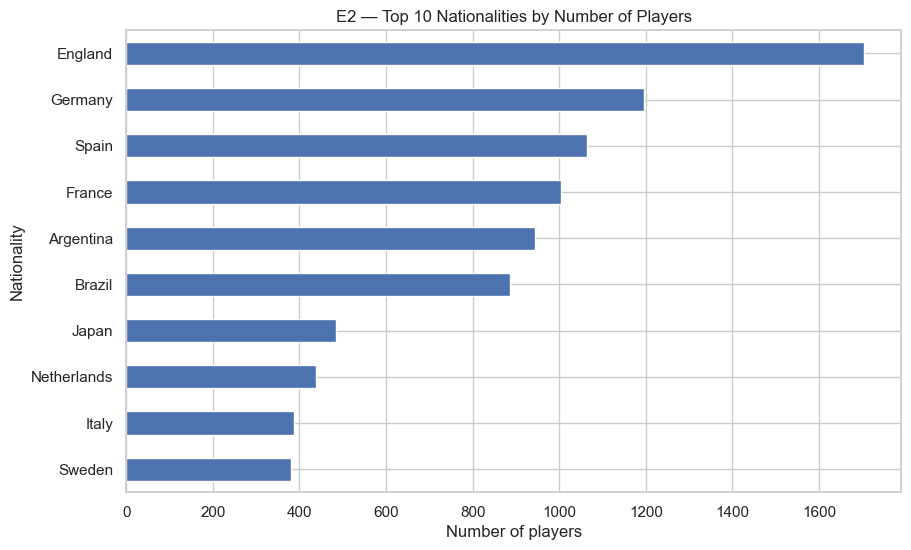

,Observation
0,"The most represented nationality is England, w..."


In [40]:
# E2 — top 10 nationalities by number of players
top_nat = clean["Nationality"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
top_nat.plot.barh()
plt.title("E2 — Top 10 Nationalities by Number of Players")
plt.xlabel("Number of players")
plt.ylabel("Nationality")
plt.show()

observation(f"The most represented nationality is {clean['Nationality'].value_counts().idxmax()}, with {clean['Nationality'].value_counts().max()} players in the dataset.")

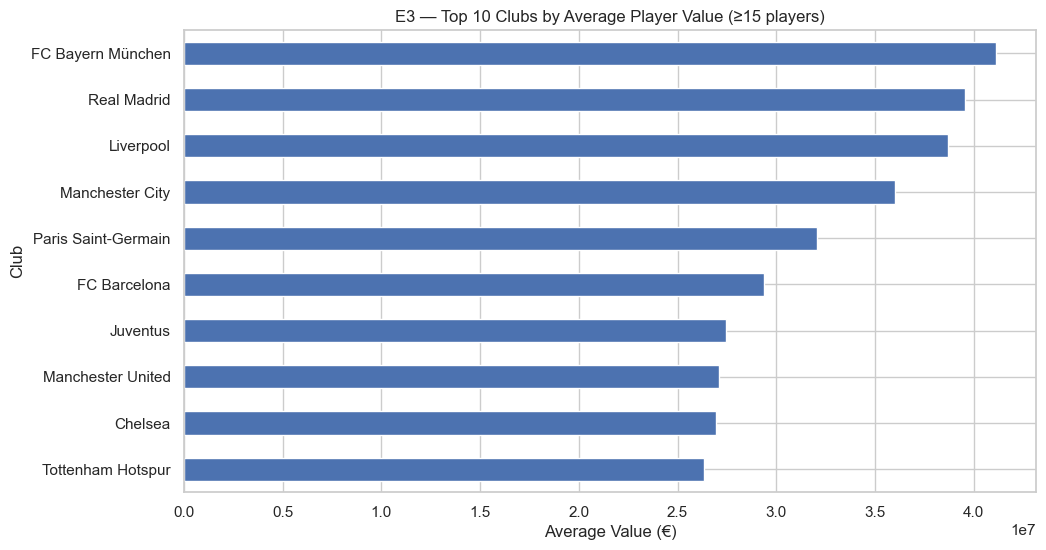

,Observation
0,"Among clubs with at least 15 players, FC Bayer..."


In [41]:
# E3 — top 10 clubs by average Value, only clubs with at least 15 players
club_counts = clean["Club"].value_counts()
eligible_clubs = club_counts[club_counts >= 15].index
club_avg_value = clean[clean["Club"].isin(eligible_clubs)].groupby("Club")["Value"].mean().sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(11, 6))
club_avg_value.plot.barh()
plt.title("E3 — Top 10 Clubs by Average Player Value (≥15 players)")
plt.xlabel("Average Value (€)")
plt.ylabel("Club")
plt.show()

observation(f"Among clubs with at least 15 players, {club_avg_value.index[-1]} has the highest average player Value in this dataset.")

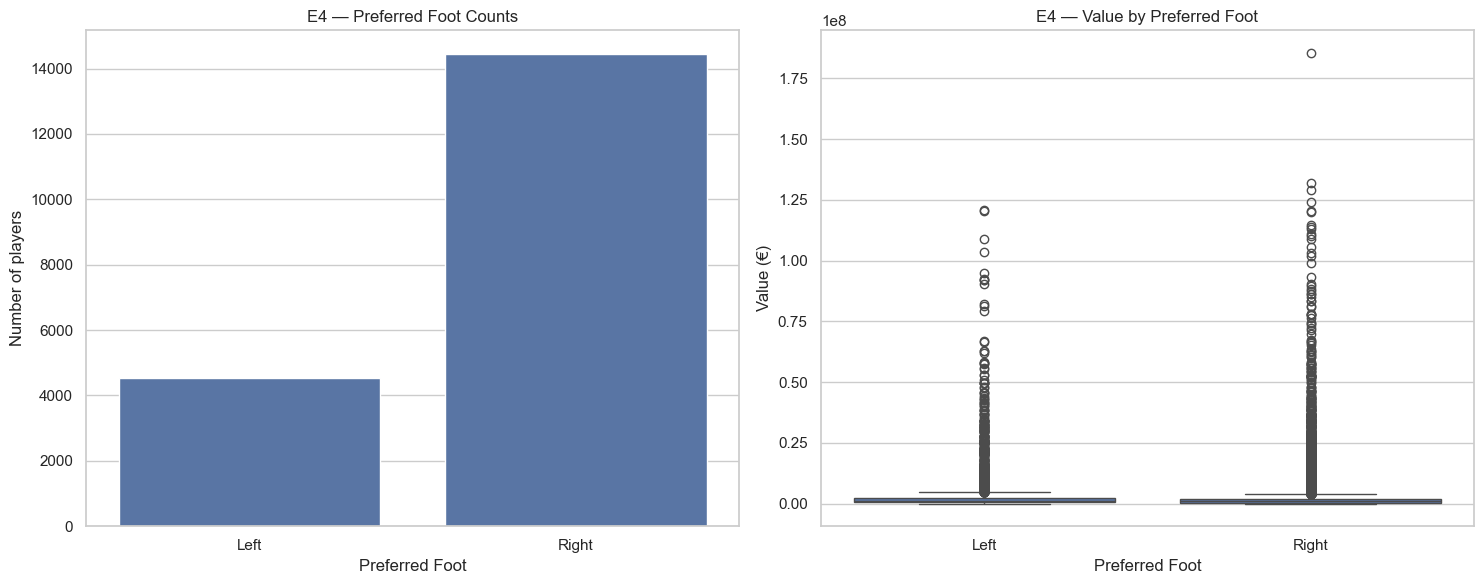

,Observation
0,The average Values are {'Left': 3151647.551830...


In [42]:
# E4 — Preferred Foot count and Value boxplot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.countplot(data=clean, x="Preferred Foot", ax=axes[0])
axes[0].set_title("E4 — Preferred Foot Counts")
axes[0].set_xlabel("Preferred Foot")
axes[0].set_ylabel("Number of players")

sns.boxplot(data=clean, x="Preferred Foot", y="Value", ax=axes[1])
axes[1].set_title("E4 — Value by Preferred Foot")
axes[1].set_xlabel("Preferred Foot")
axes[1].set_ylabel("Value (€)")

plt.tight_layout()
plt.show()

foot_means = clean.groupby("Preferred Foot")["Value"].mean()
observation(f"The average Values are {foot_means.to_dict()}. The boxplots overlap substantially, so preferred foot alone does not appear to create a large separation in Value.")

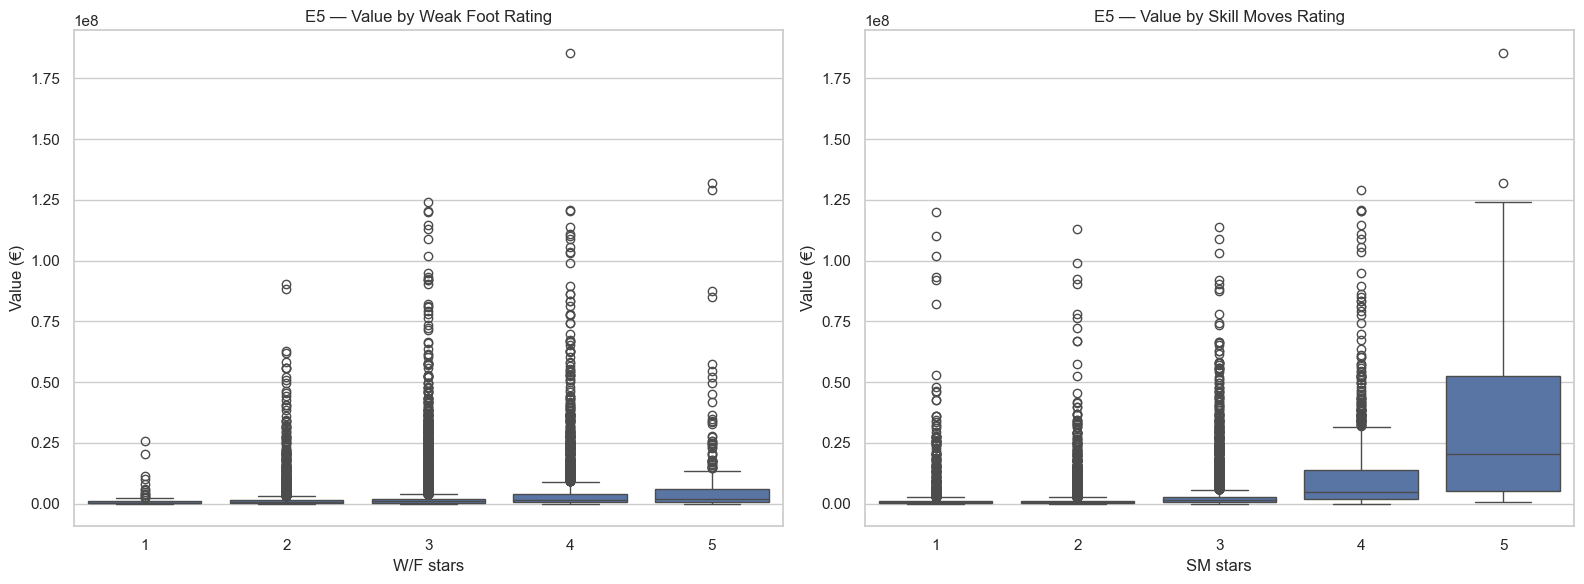

,Observation
0,Higher W/F and SM star groups generally contai...


In [43]:
# E5 — Value by W/F and SM
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=clean, x="W/F", y="Value", ax=axes[0])
axes[0].set_title("E5 — Value by Weak Foot Rating")
axes[0].set_xlabel("W/F stars")
axes[0].set_ylabel("Value (€)")

sns.boxplot(data=clean, x="SM", y="Value", ax=axes[1])
axes[1].set_title("E5 — Value by Skill Moves Rating")
axes[1].set_xlabel("SM stars")
axes[1].set_ylabel("Value (€)")

plt.tight_layout()
plt.show()

observation("Higher W/F and SM star groups generally contain higher-valued players, although there is considerable variation within each star rating.")

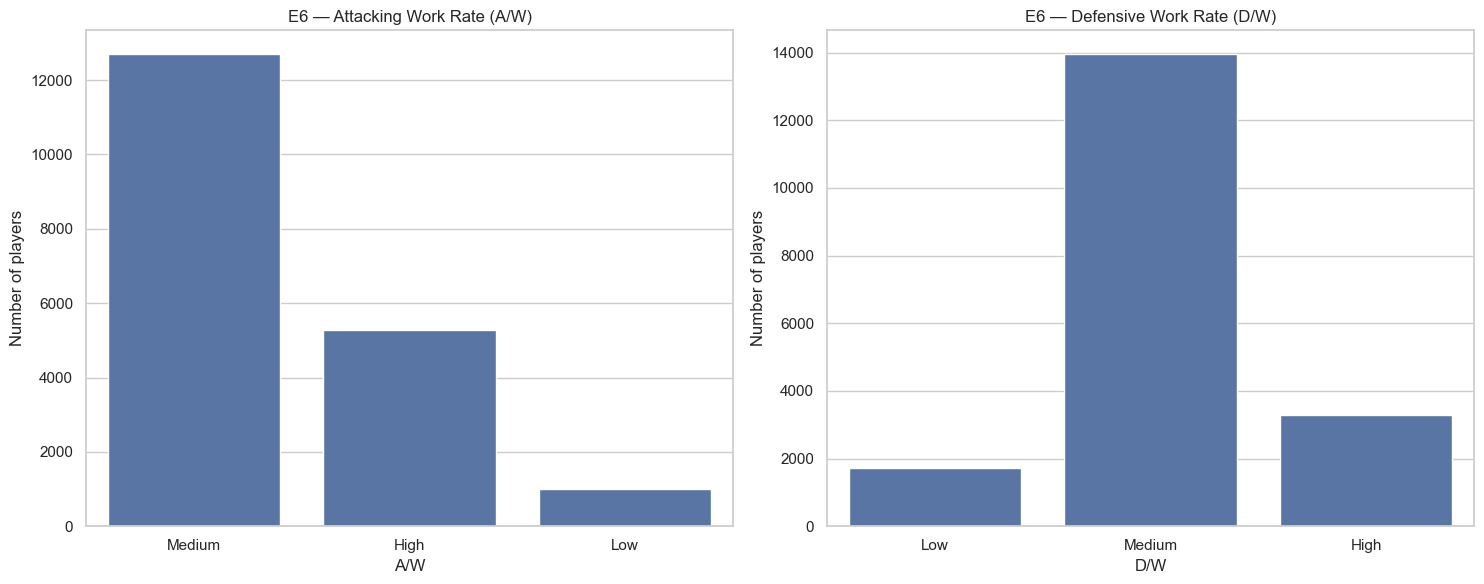

,Observation
0,"The most common attacking work rate is Medium,..."


In [44]:
# E6 — A/W and D/W count plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.countplot(data=clean, x="A/W", ax=axes[0])
axes[0].set_title("E6 — Attacking Work Rate (A/W)")
axes[0].set_xlabel("A/W")
axes[0].set_ylabel("Number of players")

sns.countplot(data=clean, x="D/W", ax=axes[1])
axes[1].set_title("E6 — Defensive Work Rate (D/W)")
axes[1].set_xlabel("D/W")
axes[1].set_ylabel("Number of players")

plt.tight_layout()
plt.show()

aw_mode = clean["A/W"].mode().iloc[0]
dw_mode = clean["D/W"].mode().iloc[0]
observation(f"The most common attacking work rate is {aw_mode}, and the most common defensive work rate is {dw_mode}.")

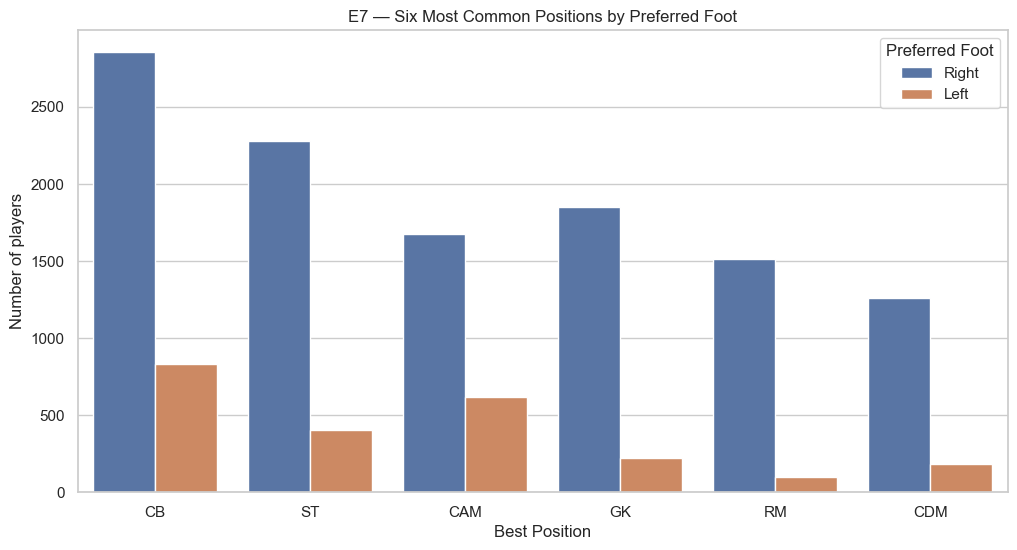

,Observation
0,The position groups generally contain both lef...


In [45]:
# E7 (Extra) — six most common positions split by Preferred Foot
six_positions = clean["Best Position"].value_counts().head(6).index

plt.figure(figsize=(12, 6))
sns.countplot(
    data=clean[clean["Best Position"].isin(six_positions)],
    x="Best Position",
    hue="Preferred Foot",
    order=six_positions
)
plt.title("E7 — Six Most Common Positions by Preferred Foot")
plt.xlabel("Best Position")
plt.ylabel("Number of players")
plt.legend(title="Preferred Foot")
plt.show()

observation("The position groups generally contain both left- and right-footed players. Any visible dominance is position-specific rather than a universal pattern across all six positions.")

## Part F — Raw versus cleaned

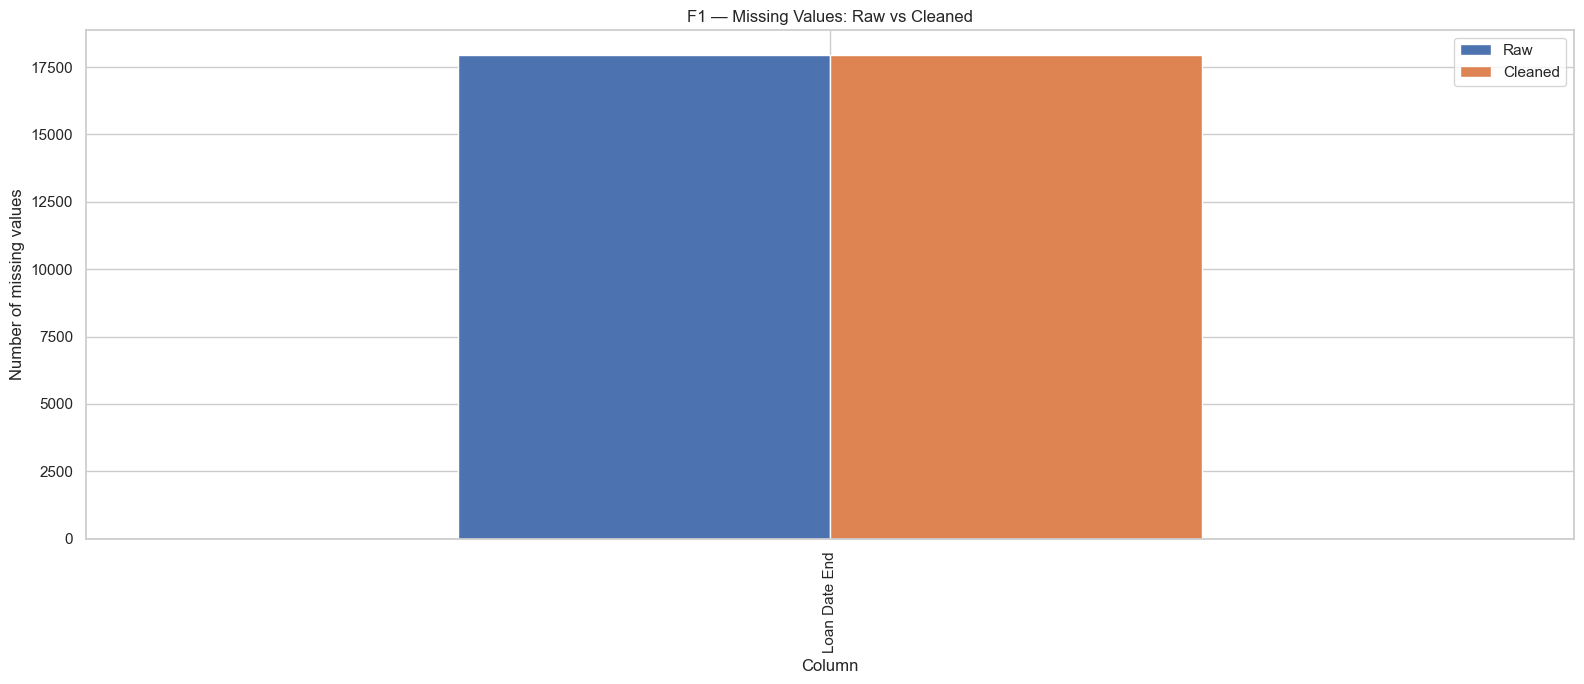

,Observation
0,The comparison shows where cleaning reduced or...


In [46]:
# F1 — compare missing values for the same columns
common_cols = raw.columns.intersection(clean.columns)
raw_common_missing = raw[common_cols].isnull().sum()
clean_common_missing = clean[common_cols].isnull().sum()

f1 = pd.DataFrame({"Raw": raw_common_missing, "Cleaned": clean_common_missing})
f1_plot = f1[(f1["Raw"] > 0) | (f1["Cleaned"] > 0)].sort_values("Raw", ascending=False)

ax = f1_plot.plot.bar(figsize=(16, 7))
ax.set_title("F1 — Missing Values: Raw vs Cleaned")
ax.set_xlabel("Column")
ax.set_ylabel("Number of missing values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

observation("The comparison shows where cleaning reduced or changed missing values. The exact differences depend on the cleaning performed in the previous lab.")

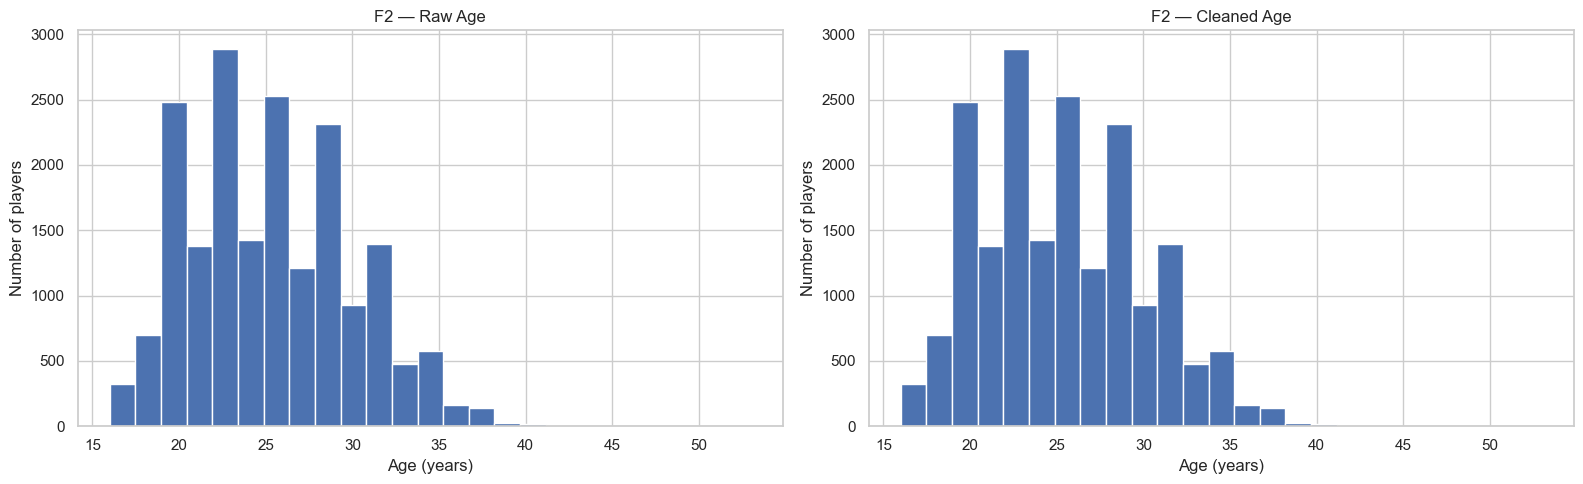

,Observation
0,Age should have the same overall distribution ...


In [47]:
# F2 — Age histograms, raw vs cleaned
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(pd.to_numeric(raw["Age"], errors="coerce").dropna(), bins=25)
axes[0].set_title("F2 — Raw Age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of players")

axes[1].hist(pd.to_numeric(clean["Age"], errors="coerce").dropna(), bins=25)
axes[1].set_title("F2 — Cleaned Age")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Number of players")

plt.tight_layout()
plt.show()
observation("Age should have the same overall distribution if it was already numeric and cleaning did not alter its values. Any small difference can come from missing-value handling or formatting in the raw file.")

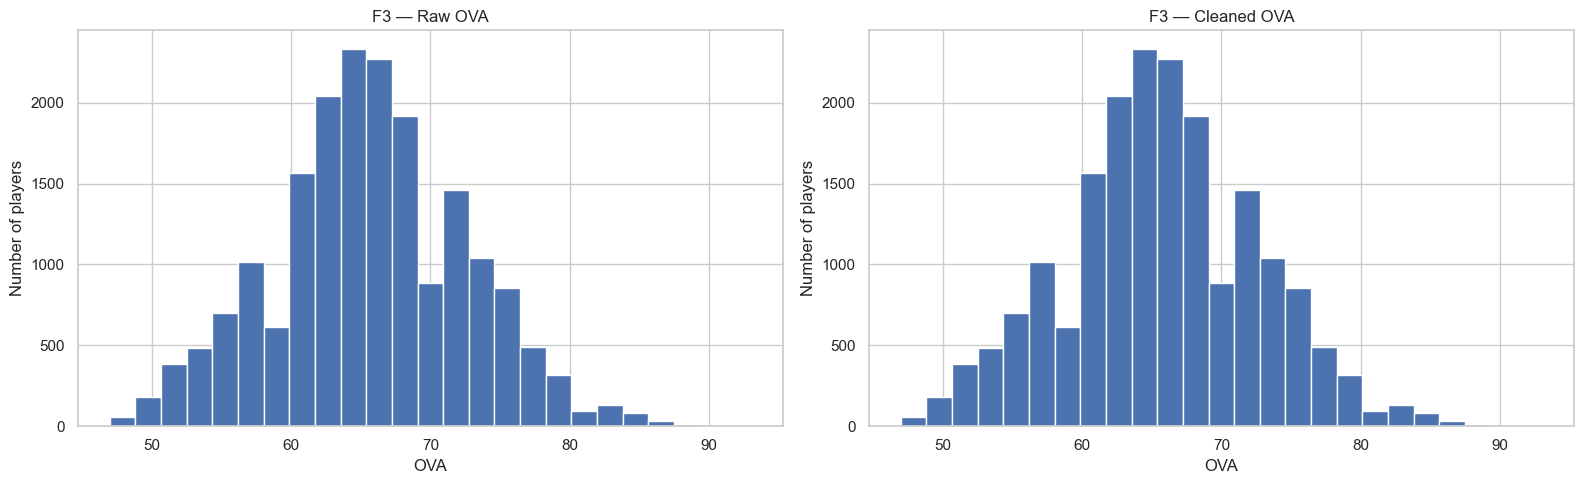

,Observation
0,The raw OVA column is explicitly named ↓OVA in...


In [48]:
# F3 — OVA histograms, raw vs cleaned
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(pd.to_numeric(raw[raw_ova_col], errors="coerce").dropna(), bins=25)
axes[0].set_title("F3 — Raw OVA")
axes[0].set_xlabel("OVA")
axes[0].set_ylabel("Number of players")

axes[1].hist(pd.to_numeric(clean[clean_ova_col], errors="coerce").dropna(), bins=25)
axes[1].set_title("F3 — Cleaned OVA")
axes[1].set_xlabel("OVA")
axes[1].set_ylabel("Number of players")

plt.tight_layout()
plt.show()
observation("The raw OVA column is explicitly named ↓OVA in the assignment, while the cleaned file uses OVA. After numeric conversion, the distributions should closely match because cleaning is intended to make the field usable rather than change its meaning.")

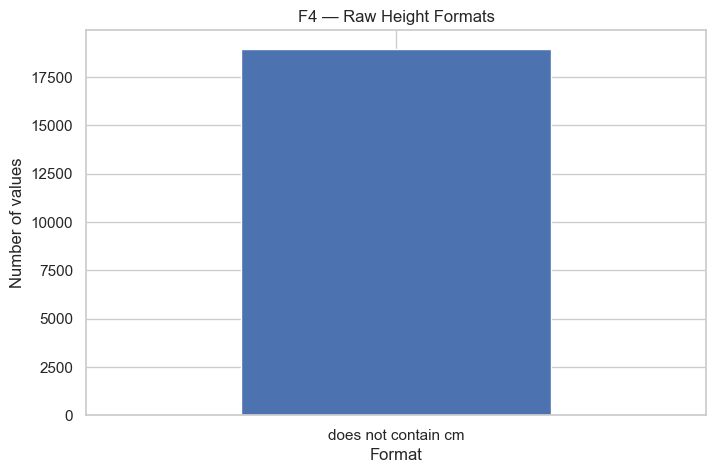

,Observation
0,Most raw Height values contain the unit 'cm'. ...


In [49]:
# F4 — raw Height formats: cm vs not cm
height_raw = raw["Height"].astype("string")
height_format = pd.Series(
    np.where(height_raw.str.contains("cm", case=False, na=False), "contains cm", "does not contain cm"),
    index=raw.index
)
height_counts = height_format.value_counts()

plt.figure(figsize=(8, 5))
height_counts.plot.bar()
plt.title("F4 — Raw Height Formats")
plt.xlabel("Format")
plt.ylabel("Number of values")
plt.xticks(rotation=0)
plt.show()

observation("Most raw Height values contain the unit 'cm'. The other group contains differently formatted or missing/non-standard entries and therefore needs cleaning before numeric analysis.")

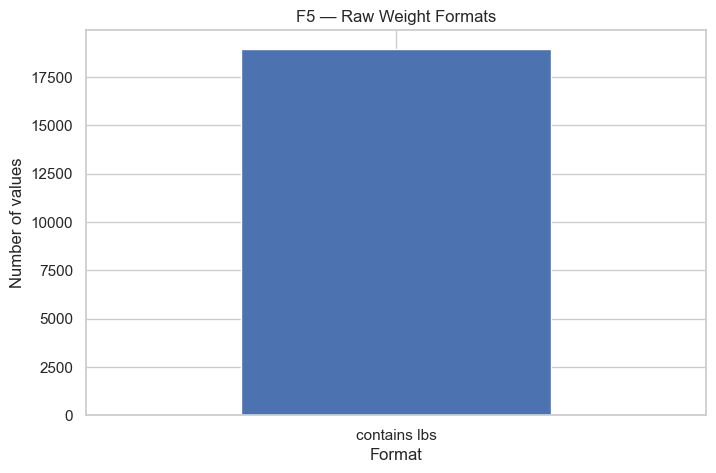

,Observation
0,Raw Weight contains values written with units ...


In [50]:
# F5 — raw Weight formats: kg vs lbs
weight_raw = raw["Weight"].astype("string")
weight_format = pd.Series(
    np.select(
        [
            weight_raw.str.contains("kg", case=False, na=False),
            weight_raw.str.contains("lbs", case=False, na=False)
        ],
        ["contains kg", "contains lbs"],
        default="other/missing"
    ),
    index=raw.index
)
weight_counts = weight_format.value_counts()

plt.figure(figsize=(8, 5))
weight_counts.plot.bar()
plt.title("F5 — Raw Weight Formats")
plt.xlabel("Format")
plt.ylabel("Number of values")
plt.xticks(rotation=0)
plt.show()

observation("Raw Weight contains values written with units such as kg and lbs. These textual units prevent direct numeric analysis until the cleaning step converts them into a consistent numeric representation.")

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14544\1268028790.py:13: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


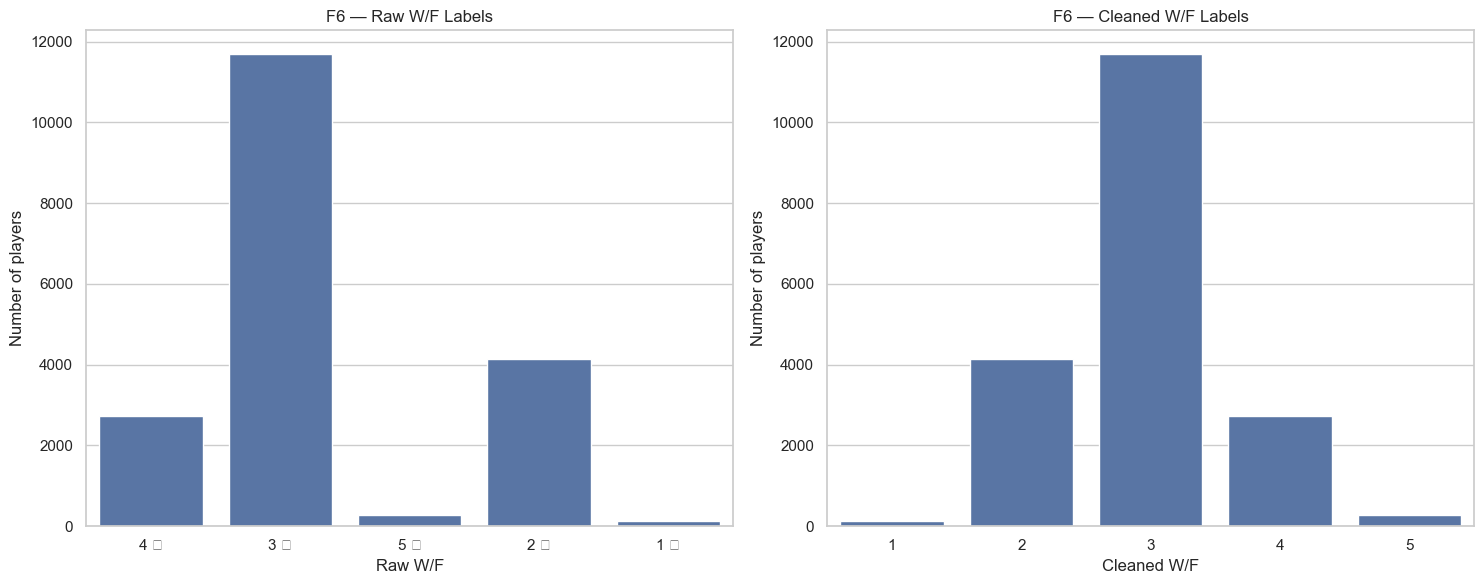

,Observation
0,"The raw W/F field uses text/star-style labels,..."


In [51]:
# F6 — raw W/F vs cleaned W/F
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.countplot(data=raw, x="W/F", ax=axes[0])
axes[0].set_title("F6 — Raw W/F Labels")
axes[0].set_xlabel("Raw W/F")
axes[0].set_ylabel("Number of players")

sns.countplot(data=clean, x="W/F", ax=axes[1])
axes[1].set_title("F6 — Cleaned W/F Labels")
axes[1].set_xlabel("Cleaned W/F")
axes[1].set_ylabel("Number of players")

plt.tight_layout()
plt.show()

observation("The raw W/F field uses text/star-style labels, whereas the cleaned field is represented in a consistent rating format suitable for grouping and numeric comparison.")

In [52]:
# F7 — table of at least 6 visible changes between raw and cleaned files
comparison_rows = [
    ["Value", "Text/currency formatting", "Numeric value"],
    ["Wage", "Text/currency formatting", "Numeric value"],
    ["Height", "Unit text such as cm", "Numeric centimetres"],
    ["Weight", "Unit text such as kg/lbs", "Numeric weight"],
    ["Hits", "Text suffixes such as K/M", "Numeric count"],
    [f"{raw_ova_col} → {clean_ova_col}", "Raw OVA naming/format", "Cleaned numeric OVA"],
    ["W/F", "Star/text labels", "Consistent rating representation"],
    ["Missing values", "More raw missing/non-standard entries", "Reduced/standardized after cleaning"]
]
comparison_table = pd.DataFrame(comparison_rows, columns=["Column", "Raw file", "Cleaned file"])
display(comparison_table.style.hide(axis="index"))

observation("The biggest changes are the conversion of text-formatted numeric fields into numeric values and the standardization of categorical/rating formats. This makes plotting and correlation analysis reliable.")

Column,Raw file,Cleaned file
Value,Text/currency formatting,Numeric value
Wage,Text/currency formatting,Numeric value
Height,Unit text such as cm,Numeric centimetres
Weight,Unit text such as kg/lbs,Numeric weight
Hits,Text suffixes such as K/M,Numeric count
↓OVA → OVA,Raw OVA naming/format,Cleaned numeric OVA
W/F,Star/text labels,Consistent rating representation
Missing values,More raw missing/non-standard entries,Reduced/standardized after cleaning


,Observation
0,The biggest changes are the conversion of text...


In [53]:
# F8 — concise explanation
f8_text = (
    "Before cleaning, fields such as Value, Wage, Height, Weight and Hits could not be treated as ordinary numeric columns "
    "because they contained currency symbols, units, K/M suffixes or other text. Cleaning matters because statistical plots, "
    "correlations and numeric comparisons require consistent numeric values. Without cleaning, plots can fail or give misleading results."
)
print(f8_text)


Before cleaning, fields such as Value, Wage, Height, Weight and Hits could not be treated as ordinary numeric columns because they contained currency symbols, units, K/M suffixes or other text. Cleaning matters because statistical plots, correlations and numeric comparisons require consistent numeric values. Without cleaning, plots can fail or give misleading results.


## Final Summary
The assignment asks for 5–8 lines covering the most important findings about Value, its strongest relationships, repeated information, the raw-vs-cleaned difference, and one question for the next lab.

In [54]:
# Automatically generated final summary from the results above
strongest_value_relation = value_corr.index[-1]
strongest_value_r = value_corr.iloc[-1]

print(
    f"1. Player Value is strongly right-skewed, with most players at lower values and a small group of extremely valuable players.\n"
    f"2. The strongest relationship with Value among the selected variables is {strongest_value_relation} (r={strongest_value_r:.2f}).\n"
    f"3. Several player-skill columns repeat related information; for example, the attacking/skill heatmap shows strong positive relationships among technical skills.\n"
    f"4. The biggest raw-vs-cleaned difference is that fields such as Value, Wage, Height, Weight and Hits become consistently numeric after cleaning.\n"
    f"5. The raw file also contains formatting differences such as ↓OVA versus OVA and text/star labels in rating fields.\n"
    f"6. A useful next-lab question is: which combination of player attributes predicts Value most accurately?"
)

1. Player Value is strongly right-skewed, with most players at lower values and a small group of extremely valuable players.
2. The strongest relationship with Value among the selected variables is Wage (r=0.81).
3. Several player-skill columns repeat related information; for example, the attacking/skill heatmap shows strong positive relationships among technical skills.
4. The biggest raw-vs-cleaned difference is that fields such as Value, Wage, Height, Weight and Hits become consistently numeric after cleaning.
5. The raw file also contains formatting differences such as ↓OVA versus OVA and text/star labels in rating fields.
6. A useful next-lab question is: which combination of player attributes predicts Value most accurately?


## Submission checklist

- [ ] Put `fifa21_raw_data.csv` and `fifa21_cleaned_data.csv` in the same folder as this notebook.
- [ ] Run **Kernel → Restart and Run All**.
- [ ] Check that every plot has a title and labelled axes.
- [ ] Review the automatically generated observations and adjust wording into your own words if your instructor requires handwritten/original observations.
- [ ] Save as `RollNo_Name_EDA.ipynb` as required by the assignment.
- [ ] If submitting online, compress the notebook as `RollNo_Name_EDA.zip`.

The supplied assignment specifies the notebook order and submission naming on page 5. fileciteturn0file0L252-L264